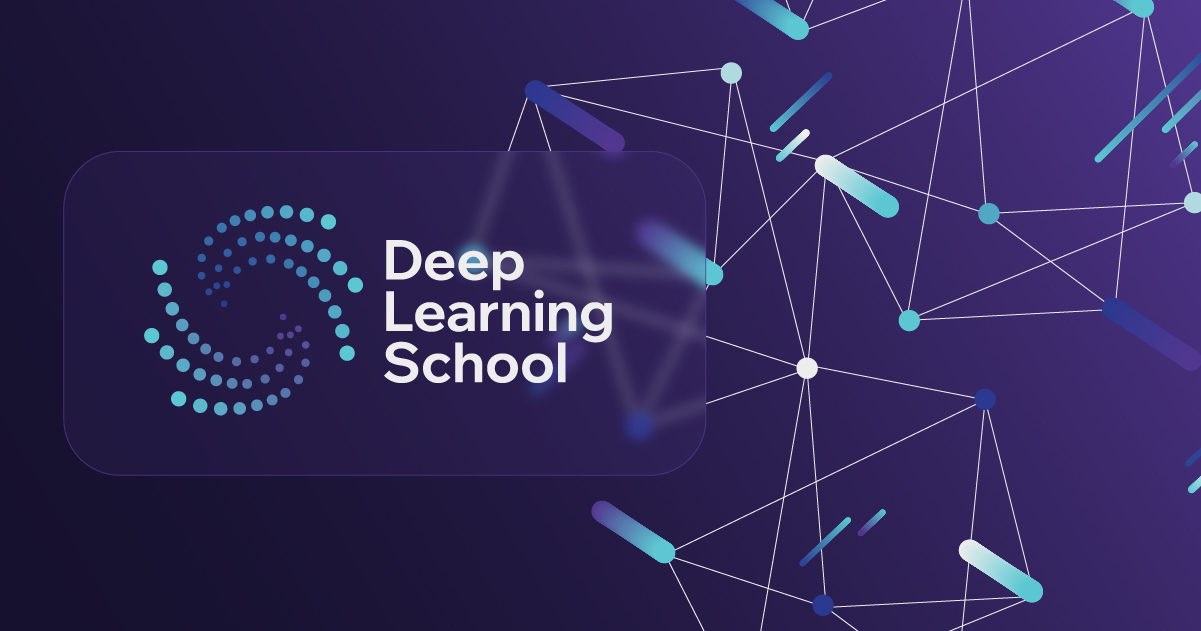

<h3 style="text-align: center;"><b>Школа глубокого обучения ФПМИ МФТИ</b></h3>

<h1 style="text-align: center;"><b>Домашнее задание. Обучение языковой модели с помощью LSTM </b></h1>


В этом задании Вам предстоит обучить языковую модель с помощью рекуррентной нейронной сети. В отличие от семинарского занятия, Вам необходимо будет работать с отдельными словами, а не буквами.


Установим модуль ```datasets```, чтобы нам проще было работать с данными.

In [1]:
# !pip install datasets

Импорт необходимых библиотек

In [2]:
import os
import random
import numpy as np
import torch
import sys

def set_seed(seed=42):
    """
    Фиксация источников случайности
    """
    random.seed(seed)
    np.random.seed(seed)
    torch.manual_seed(seed)
 
    if torch.cuda.is_available():
        torch.cuda.manual_seed(seed)
        torch.cuda.manual_seed_all(seed)

    # Детерминированные алгоритмы
    torch.backends.cudnn.deterministic = True
    torch.backends.cudnn.benchmark = False
    
    # Фиксация хэшей Python
    os.environ['PYTHONHASHSEED'] = str(seed)
    
    # Для CUDA
    os.environ['CUBLAS_WORKSPACE_CONFIG'] = ':16:8'
    # os.environ['CUBLAS_WORKSPACE_CONFIG'] = ':4096:8'   

# Фиксация случайности
SEED = 42
set_seed(SEED)

In [3]:
# import torch
import torch.nn as nn
from torch.utils.data import Dataset, DataLoader

# import numpy as np
import matplotlib.pyplot as plt

from tqdm.auto import tqdm
from datasets import load_dataset
from nltk.tokenize import sent_tokenize, word_tokenize
from sklearn.model_selection import train_test_split
import nltk

from collections import Counter
from typing import List

import math

import seaborn
seaborn.set_theme(palette='summer')

In [4]:
# nltk.download('punkt')

In [5]:
device = 'cuda' if torch.cuda.is_available() else 'cpu'
device

'cuda'

In [6]:
NUM_EPOCH = 7

## Подготовка данных

Воспользуемся датасетом imdb. В нем хранятся отзывы о фильмах с сайта imdb. Загрузим данные с помощью функции ```load_dataset```

In [7]:
# Загрузим датасет
dataset = load_dataset('imdb')

### Препроцессинг данных и создание словаря (1 балл)

Далее вам необходмо самостоятельно произвести препроцессинг данных и получить словарь или же просто ```set``` строк. Что необходимо сделать:

1. Разделить отдельные тренировочные примеры на отдельные предложения с помощью функции ```sent_tokenize``` из бибилиотеки ```nltk```. Каждое отдельное предложение будет одним тренировочным примером.
2. Оставить только те предложения, в которых меньше ```word_threshold``` слов.
3. Посчитать частоту вхождения каждого слова в оставшихся предложениях. Для деления предлоения на отдельные слова удобно использовать функцию ```word_tokenize```.
4. Создать объект ```vocab``` класса ```set```, положить в него служебные токены '\<unk\>', '\<bos\>', '\<eos\>', '\<pad\>' и vocab_size самых частовстречающихся слов.   

Посмотрим на примеры текстов

In [8]:
display(dataset['train']['text'][:7])

['I rented I AM CURIOUS-YELLOW from my video store because of all the controversy that surrounded it when it was first released in 1967. I also heard that at first it was seized by U.S. customs if it ever tried to enter this country, therefore being a fan of films considered "controversial" I really had to see this for myself.<br /><br />The plot is centered around a young Swedish drama student named Lena who wants to learn everything she can about life. In particular she wants to focus her attentions to making some sort of documentary on what the average Swede thought about certain political issues such as the Vietnam War and race issues in the United States. In between asking politicians and ordinary denizens of Stockholm about their opinions on politics, she has sex with her drama teacher, classmates, and married men.<br /><br />What kills me about I AM CURIOUS-YELLOW is that 40 years ago, this was considered pornographic. Really, the sex and nudity scenes are few and far between, e

In [9]:
sentences = []
word_threshold = 32

# Получить отдельные предложения и поместить их в sentences
for sentence in tqdm(dataset['train']['text']):
    sentences.extend(
        [x.lower() for x in sent_tokenize(sentence) if len(word_tokenize(x.lower())) < word_threshold]
    )

  0%|          | 0/25000 [00:00<?, ?it/s]

In [10]:
print("Всего предложений:", len(sentences))

Всего предложений: 198801


Посчитаем для каждого слова его встречаемость.

In [11]:
words = Counter()

# Расчет встречаемости слов
for sentence in tqdm(sentences):
    for word in word_tokenize(sentence):
        words[word] += 1

  0%|          | 0/198801 [00:00<?, ?it/s]

In [12]:
len(words)

68415

Добавим в словарь ```vocab_size``` самых встречающихся слов.

In [13]:
vocab = set()
vocab_size = 40000

# Наполнение словаря
vocab = set(['<unk>', '<bos>', '<eos>', '<pad>'])

# Топ слов (длиной равной vocab_size)
words_most_common = [word for word, _ in words.most_common(vocab_size)]
vocab.update(words_most_common)

In [14]:
assert '<unk>' in vocab
assert '<bos>' in vocab
assert '<eos>' in vocab
assert '<pad>' in vocab
assert len(vocab) == vocab_size + 4

In [15]:
print("Всего слов в словаре:", len(vocab))

Всего слов в словаре: 40004


### Подготовка датасета (1 балл)

Далее, как и в семинарском занятии, подготовим датасеты и даталоадеры.

В классе ```WordDataset``` вам необходимо реализовать метод ```__getitem__```, который будет возвращать сэмпл данных по входному idx, то есть список целых чисел (индексов слов).

Внутри этого метода необходимо добавить служебные токены начала и конца последовательности, а также токенизировать соответствующее предложение с помощью ```word_tokenize``` и сопоставить ему индексы из ```word2ind```.

In [16]:
word2ind = {char: i for i, char in enumerate(vocab)}
ind2word = {i: char for char, i in word2ind.items()}

In [17]:
class WordDataset:
    def __init__(self, sentences):
        self.data = sentences
        self.unk_id = word2ind['<unk>']
        self.bos_id = word2ind['<bos>']
        self.eos_id = word2ind['<eos>']
        self.pad_id = word2ind['<pad>']

    def __getitem__(self, idx: int) -> List[int]:
        tokenized_sentence = []
        # Допишите код здесь
        tokenized_sentence += [self.bos_id]
        tokenized_sentence += [word2ind.get(word, self.unk_id) for word in word_tokenize(self.data[idx])]
        tokenized_sentence += [self.eos_id]        

        return tokenized_sentence

    def __len__(self) -> int:
        return len(self.data)

In [18]:
def collate_fn_with_padding(
    input_batch: List[List[int]], pad_id=word2ind['<pad>']) -> torch.Tensor:
    seq_lens = [len(x) for x in input_batch]
    max_seq_len = max(seq_lens)

    new_batch = []
    for sequence in input_batch:
        for _ in range(max_seq_len - len(sequence)):
            sequence.append(pad_id)
        new_batch.append(sequence)

    sequences = torch.LongTensor(new_batch).to(device)

    new_batch = {
        'input_ids': sequences[:,:-1],
        'target_ids': sequences[:,1:]
    }

    return new_batch

In [19]:
train_sentences, temp_sentences = train_test_split(sentences, test_size=0.2, random_state=42)
val_sentences, test_sentences = train_test_split(temp_sentences, test_size=0.5, random_state=42)

train_dataset = WordDataset(train_sentences)
val_dataset = WordDataset(val_sentences)
test_dataset = WordDataset(test_sentences)

batch_size = 128

train_dataloader = DataLoader(
    train_dataset, collate_fn=collate_fn_with_padding, batch_size=batch_size)

val_dataloader = DataLoader(
    val_dataset, collate_fn=collate_fn_with_padding, batch_size=batch_size)

test_dataloader = DataLoader(
    test_dataset, collate_fn=collate_fn_with_padding, batch_size=batch_size)

## Обучение и архитектура модели

Вам необходимо на практике проверить, что влияет на качество языковых моделей. В этом задании нужно провести серию экспериментов с различными вариантами языковых моделей и сравнить различия в конечной перплексии на тестовом множестве.

Возмоэные идеи для экспериментов:

* Различные RNN-блоки, например, LSTM или GRU. Также можно добавить сразу несколько RNN блоков друг над другом с помощью аргумента num_layers. Вам поможет официальная документация [здесь](https://pytorch.org/docs/stable/generated/torch.nn.LSTM.html)
* Различные размеры скрытого состояния. Различное количество линейных слоев после RNN-блока. Различные функции активации.
* Добавление нормализаций в виде Dropout, BatchNorm или LayerNorm
* Различные аргументы для оптимизации, например, подбор оптимального learning rate или тип алгоритма оптимизации SGD, Adam, RMSProp и другие
* Любые другие идеи и подходы

После проведения экспериментов необходимо составить таблицу результатов, в которой описан каждый эксперимент и посчитана перплексия на тестовом множестве.

Учтите, что эксперименты, которые различаются, например, только размером скрытого состояния или количеством линейных слоев считаются, как один эксперимент.

Успехов!

### Функция evaluate (1 балл)

Заполните функцию ```evaluate```

In [20]:
# # Исходный

# def evaluate(model, criterion, dataloader) -> float:
#     model.eval()
#     losses = []
#     with torch.no_grad():
#         for batch in dataloader:
#             logits = model(batch['input_ids']).flatten(start_dim=0, end_dim=1)
#             loss = criterion(logits, batch['target_ids'].flatten())
#             losses.append(loss.item())

#     mean_loss = sum(losses) / len(losses)
#     perplexity = math.exp(mean_loss)

#     return perplexity

In [21]:
def evaluate(model, criterion, dataloader) -> float:
    model.eval()
    losses = []
    with torch.no_grad():
        for batch in dataloader:
            logits = model(batch['input_ids']).flatten(start_dim=0, end_dim=1)
            loss = criterion(
                logits, 
                batch['target_ids'].flatten()
            )
            losses.append(loss.item())

    mean_loss = sum(losses) / len(losses)
    perplexity = math.exp(mean_loss)

    return mean_loss, perplexity

### Train loop (1 балл)

Напишите функцию для обучения модели.

In [22]:
import pandas as pd

# Датасет для сбора статистик

df_stats = pd.DataFrame(columns=['Model', 'Loss', 'Perplexity', 'Diff_Loss', 'Diff_Perplexity', 'Better_than_base'])

display(df_stats)

,Model,Loss,Perplexity,Diff_Loss,Diff_Perplexity,Better_than_base


In [23]:
# # Изначально

# from IPython.display import clear_output

# def train_model(model, criterion, optimizer, 
#                 model_name='Current',
#                 plot=True,
#                 num_epoch=5,
#                 base_losses=None,
#                 base_perplexities=None,
#                 train_loader=train_dataloader, 
#                 eval_loader=eval_dataloader):
    
#     # Напишите код здесь
#     losses = []
#     perplexities = []
    
#     for epoch in range(num_epoch):
#         epoch_losses = []
#         model.train()

#         for batch in tqdm(train_loader, desc=f'Training epoch {epoch}'):
#             optimizer.zero_grad()
#             logits = model(batch['input_ids']).flatten(start_dim=0, end_dim=1)
#             loss = criterion(logits, batch['target_ids'].flatten())
#             loss.backward()
#             optimizer.step()
            
#             epoch_losses.append(loss.item())
        
#         losses.append(sum(epoch_losses) / len(epoch_losses))
#         perplexities.append(evaluate(model, criterion, eval_loader))

#         # Отрисовка графиков
#         if plot:

#             fig, axes = plt.subplots(nrows=1, ncols=2, figsize=(15, 6))
            
#             if model_name != 'GRU_Base_Model':
#                 axes[0].plot(base_losses[:epoch+1], color='b', marker='o', markersize=4, label='GRU_Base_Model')
#             axes[0].plot(losses, color='r', marker='o', markersize=4, label=model_name)

#             axes[0].set_title('Losses')
#             axes[0].set_xlabel('epoch')
#             axes[0].set_ylabel('loss')
#             axes[0].grid(True)
#             axes[0].legend()

#             if model_name != 'GRU_Base_Model':
#                 axes[1].plot(base_perplexities[:epoch+1], color='b', marker='o', markersize=4, label='GRU_Base_Model')
#             axes[1].plot(perplexities, color='r', marker='o', markersize=4, label=model_name)

#             axes[1].set_title('Perplexities')
#             axes[1].set_xlabel('epoch')
#             axes[1].set_ylabel('perplexity')
#             axes[1].grid(True)
#             axes[1].legend()

#             clear_output(wait=True)
#             plt.show()

#     # Заполнение таблицы
#     curr_model_loss = min(losses)
#     curr_model_perp = min(perplexities)

#     if model_name != 'GRU_Base_Model':
#         diff_loss = curr_model_loss - min(base_losses)
#         diff_perp = curr_model_perp - min(base_perplexities)
#         better_than_base = curr_model_perp < min(base_perplexities)
#     else:
#         diff_loss = 0
#         diff_perp = 0
#         better_than_base = False

#     data_to_add = (model_name, curr_model_loss, curr_model_perp,
#                    diff_loss, diff_perp, better_than_base)
#     if model_name in df_stats['Model'].values:
#         index = df_stats[df_stats['Model'] == model_name].index
#     else:
#         index = len(df_stats)
#     df_stats.loc[index] = data_to_add

#     print(f'Loss = {curr_model_loss}')
#     print(f'Perplexity = {curr_model_perp}')

#     # Сравнение текущей модели с базовой моделью
#     if model_name != 'GRU_Base_Model':
#         print('\nСравнение с GRU_Base_Model:')
#         print('Loss', ('Хуже', 'Лучше')[curr_model_loss < min(base_losses)], 'на', abs(diff_loss))
#         print('Perplexity', ('Хуже', 'Лучше')[curr_model_perp < min(base_perplexities)], 'на', abs(diff_perp))
    
#     return losses, perplexities

In [24]:
from IPython.display import clear_output

def train_model(model, criterion, optimizer, 
                model_name='Current',
                plot=True,
                num_epoch=5,
                base_losses=None,
                base_perplexities=None,
                train_loader=train_dataloader, 
                val_loader=val_dataloader,
                stop_epoch=3,
                stop_delta=0.001):
    
    # Напишите код здесь
    train_losses = []
    val_losses = []
    train_perps = []
    val_perps = []

    # perplexities = []

    best_perp = float('inf')
    n_stop_epoch = 0
    best_state = None
    
    for epoch in range(num_epoch):
        epoch_losses = []
        epoch_perps = []
        model.train()

        for batch in tqdm(train_loader, desc=f'Training epoch {epoch}'):
            optimizer.zero_grad()
            logits = model(batch['input_ids']).flatten(start_dim=0, end_dim=1)
            loss = criterion(logits, batch['target_ids'].flatten())
            loss.backward()

            torch.nn.utils.clip_grad_norm_(model.parameters(), max_norm=1.0)

            optimizer.step()
            
            epoch_losses.append(loss.item())
            epoch_perps.append(math.exp(loss.item()))

        train_loss = sum(epoch_losses) / len(epoch_losses)
        train_perp = math.exp(train_loss)
        val_loss, val_perp = evaluate(model, criterion, val_loader)
        
        train_losses.append(train_loss)
        val_losses.append(val_loss)
        train_perps.append(train_perp)
        val_perps.append(val_perp)

        # Условие ранней остановки
        if val_perp < best_perp - stop_delta:
            best_perp = val_perp
            best_state = {k: v.cpu().clone() for k, v in model.state_dict().items()}
            n_stop_epoch = 0
        else:
            n_stop_epoch += 1

        # # Отрисовка графиков
        # if plot:
        #     fig, axes = plt.subplots(nrows=1, ncols=2, figsize=(15, 6))
            
        #     if model_name != 'GRU_Base_Model' and base_losses is not None:
        #         axes[0].plot(base_losses[:epoch+1], color='b', marker='o', markersize=4, label='GRU_Base_Model')
        #     axes[0].plot(losses, color='r', marker='o', markersize=4, label=model_name)

        #     axes[0].set_title('Losses')
        #     axes[0].set_xlabel('epoch')
        #     axes[0].set_ylabel('loss')
        #     axes[0].grid(True)
        #     axes[0].legend()

        #     if model_name != 'GRU_Base_Model' and base_perplexities is not None:
        #         axes[1].plot(base_perplexities[:epoch+1], color='b', marker='o', markersize=4, label='GRU_Base_Model')
        #     axes[1].plot(perplexities, color='r', marker='o', markersize=4, label=model_name)

        #     axes[1].set_title('Perplexities')
        #     axes[1].set_xlabel('epoch')
        #     axes[1].set_ylabel('perplexity')
        #     axes[1].grid(True)
        #     axes[1].legend()

        #     clear_output(wait=True)
        #     plt.show()
        #     plt.close(fig)

# Отрисовка графиков
        if plot:
            fig, axes = plt.subplots(nrows=1, ncols=2, figsize=(15, 6))

            # Loss
            if model_name != 'GRU_Base_Model' and base_losses is not None:
                axes[0].plot(
                    range(1, len(base_losses) + 1), base_losses,
                    color='black', linestyle='--', linewidth=2,
                    marker='o', markersize=4, label='GRU_Base_Model (Val Loss)'
                )

            # Train Loss
            axes[0].plot(
                range(1, len(train_losses) + 1), train_losses,
                color='blue', marker='s', markersize=4, linewidth=2,
                label=f'{model_name} (Train Loss)'
            )

            # Val Loss
            axes[0].plot(
                range(1, len(val_losses) + 1), val_losses,
                color='red', marker='o', markersize=4, linewidth=2,
                label=f'{model_name} (Val Loss)'
            )

            axes[0].set_title('Losses')
            axes[0].set_xlabel('epoch')
            axes[0].set_ylabel('loss')
            axes[0].grid(True, alpha=0.3)
            axes[0].legend()

            # Perplexity
            if model_name != 'GRU_Base_Model' and base_perplexities is not None:
                axes[1].plot(
                    range(1, len(base_perplexities) + 1), base_perplexities,
                    color='black', linestyle='--', linewidth=2,
                    marker='o', markersize=4, label='GRU_Base_Model (Val Perplexity)'
                )

            # Train Perplexity
            train_perps_correct = [math.exp(l) for l in train_losses]
            axes[1].plot(
                range(1, len(train_perps_correct) + 1), train_perps_correct,
                color='blue', marker='s', markersize=4, linewidth=2,
                label=f'{model_name} (Train Perplexity)'
            )

            # Val Perplexity
            axes[1].plot(
                range(1, len(val_perps) + 1), val_perps,
                color='red', marker='o', markersize=4, linewidth=2,
                label=f'{model_name} (Val Perplexity)'
            )

            axes[1].set_title('Perplexities')
            axes[1].set_xlabel('epoch')
            axes[1].set_ylabel('perplexity')
            axes[1].grid(True, alpha=0.3)
            axes[1].legend()

            clear_output(wait=True)
            plt.tight_layout()
            plt.show()
            plt.close(fig)

        # Ранняя остановка
        if n_stop_epoch >= stop_epoch:
            break

    # Загрузка модели с лучшими весами
    model.load_state_dict(best_state)

    # Заполнение таблицы
    best_idx = int(np.argmin(val_perps))
    curr_model_loss = val_losses[best_idx]
    curr_model_perp = val_perps[best_idx]

    if model_name != 'GRU_Base_Model' and base_perplexities is not None:
        best_base_idx = int(np.argmin(base_perplexities))
        best_base_loss = base_losses[best_base_idx]
        best_base_perp = base_perplexities[best_base_idx]
    else:
        best_base_loss = 0.0
        best_base_perp = 0.0

    if model_name != 'GRU_Base_Model':
        diff_loss = curr_model_loss - best_base_loss
        diff_perp = curr_model_perp - best_base_perp
        better_than_base = curr_model_perp < best_base_perp
    else:
        diff_loss = 0
        diff_perp = 0
        better_than_base = False

    data_to_add = (model_name, curr_model_loss, curr_model_perp,
                   diff_loss, diff_perp, better_than_base)
    if model_name in df_stats['Model'].values:
        idx = df_stats[df_stats['Model'] == model_name].index
    else:
        idx = len(df_stats)
    df_stats.loc[idx] = data_to_add

    print(f'Loss = {curr_model_loss}')
    print(f'Perplexity = {curr_model_perp}')

    # Сравнение текущей модели с базовой моделью
    if model_name != 'GRU_Base_Model':
        print('\nСравнение с GRU_Base_Model:')
        print('Loss', ('Хуже', 'Лучше')[curr_model_loss < best_base_loss], 'на', abs(diff_loss))
        print('Perplexity', ('Хуже', 'Лучше')[curr_model_perp < best_base_perp], 'на', abs(diff_perp))
    
    return val_losses, val_perps

### Base model

В качестве базовой модели возьмем модель из семинара. <br>
Результаты моделей из дальнейших экспериментов будем сравнивать с базовой моделью. <br>
Оценка того, какая из моделей лучше, будет основываться на метрике Perplexity.

In [25]:
class GRU_Base_LM(nn.Module):
    def __init__(self, hidden_dim: int, vocab_size: int):
        super().__init__()
        self.embedding = nn.Embedding(vocab_size, hidden_dim)
        self.rnn = nn.GRU(hidden_dim, hidden_dim, batch_first=True)
        self.linear = nn.Linear(hidden_dim, hidden_dim)
        self.projection = nn.Linear(hidden_dim, vocab_size)

        self.non_lin = nn.Tanh()
        self.dropout = nn.Dropout(p=0.1)

    def forward(self, input_batch) -> torch.Tensor:
        embeddings = self.embedding(input_batch)  # [batch_size, seq_len, hidden_dim]
        output, _ = self.rnn(embeddings)  # [batch_size, seq_len, hidden_dim]
        output = self.dropout(self.linear(self.non_lin(output)))  # [batch_size, seq_len, hidden_dim]
        projection = self.projection(self.non_lin(output))  # [batch_size, seq_len, vocab_size]

        return projection

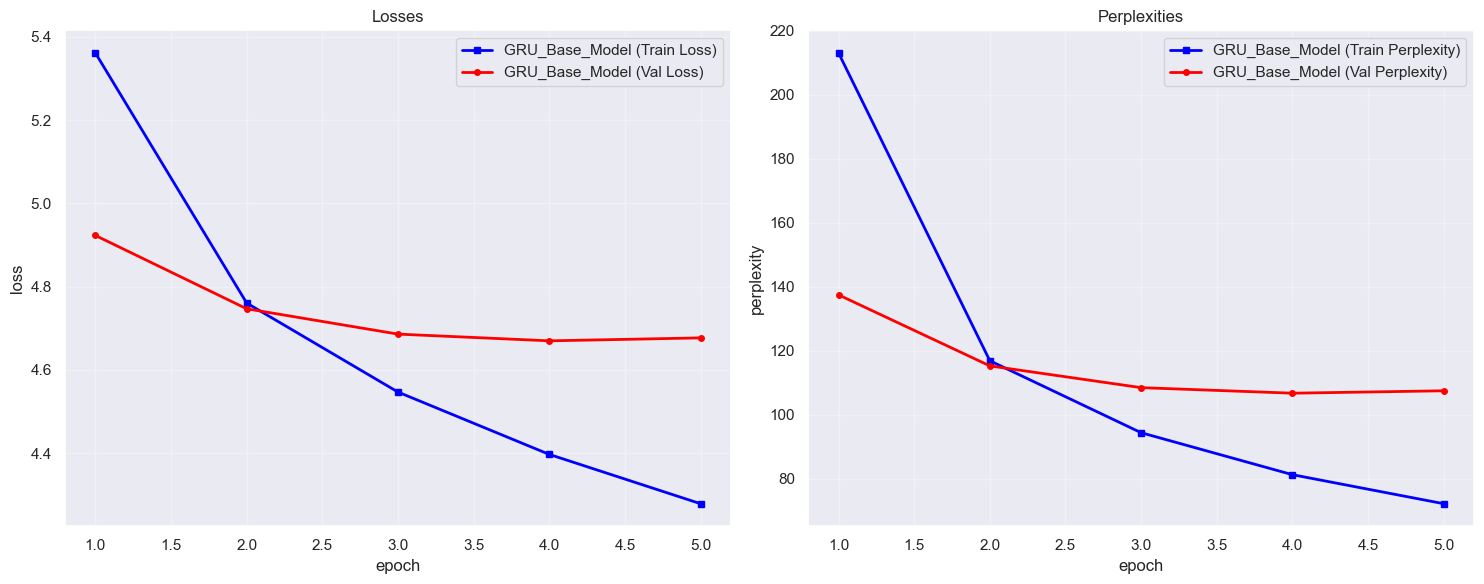

Loss = 4.669865293380542
Perplexity = 106.68337050828232


In [26]:
set_seed(SEED)

model_name = 'GRU_Base_Model'

model_gru_base = GRU_Base_LM(hidden_dim=256, vocab_size=len(vocab)).to(device)
criterion = nn.CrossEntropyLoss(ignore_index=word2ind['<pad>'])
optimizer = torch.optim.Adam(model_gru_base.parameters())

base_losses, base_perplexities = train_model(model=model_gru_base, 
                                             criterion=criterion, 
                                             optimizer=optimizer,
                                             model_name=model_name)

In [27]:
display(df_stats)

,Model,Loss,Perplexity,Diff_Loss,Diff_Perplexity,Better_than_base
0,GRU_Base_Model,4.669865,106.683371,0,0,False


### Замена GRU на LSTM (Первый эксперимент (2 балла))

Определите архитектуру модели и обучите её.

LSTM в отличии GRU лучше запоминает длинные зависимости.

In [28]:
class LSTM_LM(nn.Module):
    def __init__(self, hidden_dim: int, vocab_size: int, num_layers: int = 1):
        super().__init__()
        self.embedding = nn.Embedding(vocab_size, hidden_dim)
        self.rnn = nn.LSTM(hidden_dim, hidden_dim, num_layers=num_layers, batch_first=True)
        self.linear = nn.Linear(hidden_dim, hidden_dim)
        self.projection = nn.Linear(hidden_dim, vocab_size)

        self.non_lin = nn.Tanh()
        self.dropout = nn.Dropout(p=0.1)

    def forward(self, input_batch) -> torch.Tensor:
        embeddings = self.embedding(input_batch)
        output, _ = self.rnn(embeddings)
        output = self.dropout(self.linear(self.non_lin(output)))
        projection = self.projection(self.non_lin(output))
        
        return projection

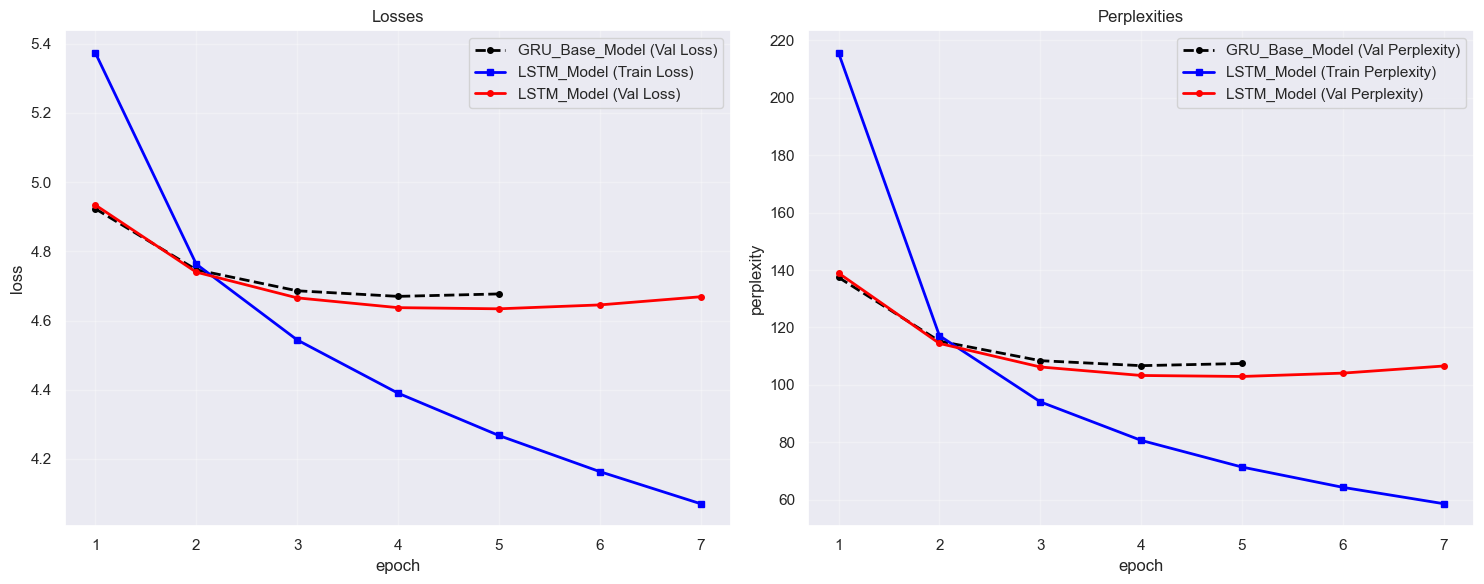

Loss = 4.633921192242549
Perplexity = 102.91683060980246

Сравнение с GRU_Base_Model:
Loss Лучше на 0.035944101137992845
Perplexity Лучше на 3.766539898479863


In [29]:
set_seed(SEED)

model_name = 'LSTM_Model'

model_lstm = LSTM_LM(hidden_dim=256, vocab_size=len(vocab), num_layers=1).to(device)
criterion = nn.CrossEntropyLoss(ignore_index=word2ind['<pad>'])
optimizer = torch.optim.Adam(model_lstm.parameters())

lstm_losses, lstm_perplexities = train_model(model=model_lstm, 
                                             criterion=criterion, 
                                             optimizer=optimizer,
                                             model_name=model_name,
                                             plot=True,
                                             num_epoch=NUM_EPOCH,
                                             base_losses=base_losses,
                                             base_perplexities=base_perplexities)

In [30]:
display(df_stats)

,Model,Loss,Perplexity,Diff_Loss,Diff_Perplexity,Better_than_base
0,GRU_Base_Model,4.669865,106.683371,0.000000,0.00000,False
1,LSTM_Model,4.633921,102.916831,-0.035944,-3.76654,True


### Использование сразу нескольких RNN блоков (Второй эксперимент (2 балла))

Попробуйте что-то поменять в модели или в пайплайне обучения, идеи для экспериментов можно подсмотреть выше.

Два блока RNN num_layers = 2. <br>
Позволит выделить более сложные иерархические зависимости.

In [31]:
class MultiLayerGRU_LM(nn.Module):
    def __init__(self, hidden_dim: int, vocab_size: int, num_layers: int = 2):
        super().__init__()
        self.embedding = nn.Embedding(vocab_size, hidden_dim)
        self.rnn = nn.GRU(hidden_dim, hidden_dim, num_layers=num_layers, batch_first=True, dropout=0.1)
        self.linear = nn.Linear(hidden_dim, hidden_dim)
        self.projection = nn.Linear(hidden_dim, vocab_size)

        self.non_lin = nn.Tanh()
        self.dropout = nn.Dropout(p=0.1)

    def forward(self, input_batch) -> torch.Tensor:
        embeddings = self.embedding(input_batch)
        output, _ = self.rnn(embeddings)
        output = self.dropout(self.linear(self.non_lin(output)))
        projection = self.projection(self.non_lin(output))
        
        return projection

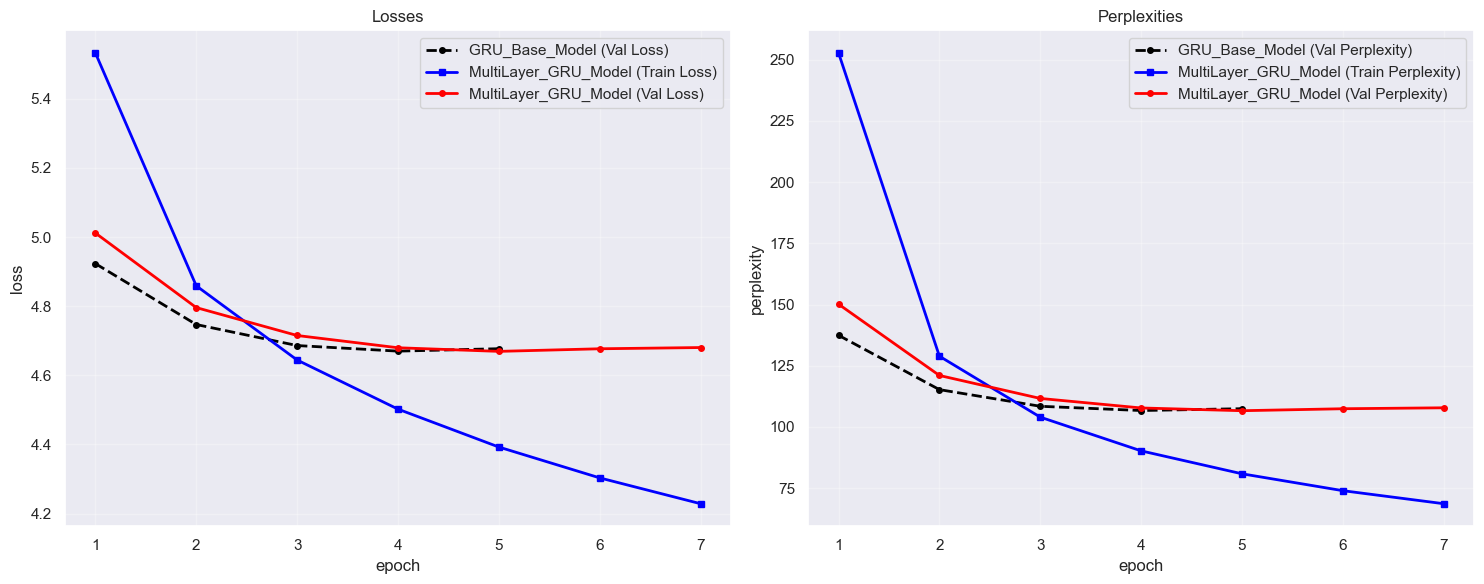

Loss = 4.669184895662161
Perplexity = 106.61080807485573

Сравнение с GRU_Base_Model:
Loss Лучше на 0.0006803977183809096
Perplexity Лучше на 0.0725624334265973


In [32]:
set_seed(SEED)

model_name = 'MultiLayer_GRU_Model'

model_multilayer_gru = MultiLayerGRU_LM(hidden_dim=256, vocab_size=len(vocab), num_layers=2).to(device) # num_layers=2
criterion = nn.CrossEntropyLoss(ignore_index=word2ind['<pad>'])
optimizer = torch.optim.Adam(model_multilayer_gru.parameters())

multilayer_losses, multilayer_perplexities = train_model(model=model_multilayer_gru, 
                                                         criterion=criterion, 
                                                         optimizer=optimizer,
                                                         model_name=model_name,
                                                         plot=True,
                                                         num_epoch=NUM_EPOCH,
                                                         base_losses=base_losses,
                                                         base_perplexities=base_perplexities)

In [33]:
display(df_stats)

,Model,Loss,Perplexity,Diff_Loss,Diff_Perplexity,Better_than_base
0,GRU_Base_Model,4.669865,106.683371,0.000000,0.000000,False
1,LSTM_Model,4.633921,102.916831,-0.035944,-3.766540,True
2,MultiLayer_GRU_Model,4.669185,106.610808,-0.000680,-0.072562,True


Далее будут ещё эксперименты

### Увеличенние размера скрытого состояния

hidden_dim=512 позволит изучить более сложные закономерности.

In [34]:
class LargerHiddenDim_LM(nn.Module):
    def __init__(self, hidden_dim: int, vocab_size: int):
        super().__init__()
        self.embedding = nn.Embedding(vocab_size, hidden_dim)
        self.rnn = nn.GRU(hidden_dim, hidden_dim, batch_first=True)
        self.linear = nn.Linear(hidden_dim, hidden_dim)
        self.projection = nn.Linear(hidden_dim, vocab_size)

        self.non_lin = nn.Tanh()
        self.dropout = nn.Dropout(p=0.1)

    def forward(self, input_batch) -> torch.Tensor:
        embeddings = self.embedding(input_batch)
        output, _ = self.rnn(embeddings)
        output = self.dropout(self.linear(self.non_lin(output)))
        projection = self.projection(self.non_lin(output))
        
        return projection

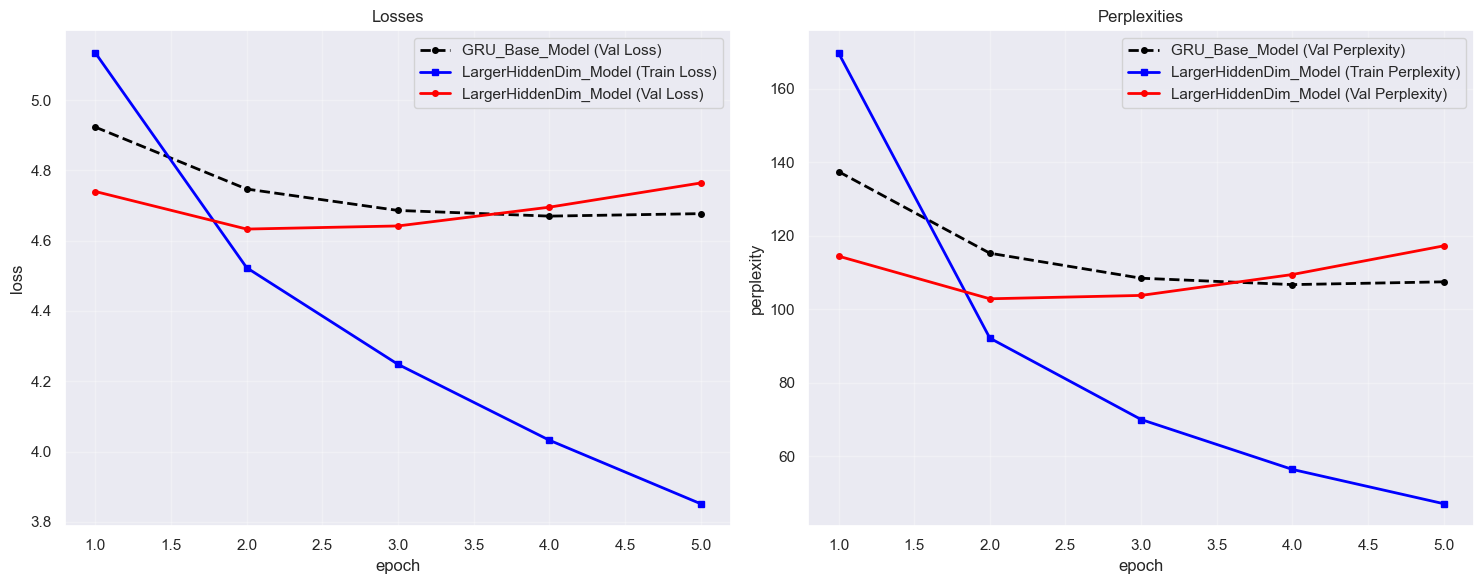

Loss = 4.633033000505888
Perplexity = 102.82546131402489

Сравнение с GRU_Base_Model:
Loss Лучше на 0.03683229287465384
Perplexity Лучше на 3.857909194257431


In [35]:
set_seed(SEED)

model_name = 'LargerHiddenDim_Model'

model_larger_hidden = LargerHiddenDim_LM(hidden_dim=512, vocab_size=len(vocab)).to(device) # hidden_dim=512
criterion = nn.CrossEntropyLoss(ignore_index=word2ind['<pad>'])
optimizer = torch.optim.Adam(model_larger_hidden.parameters())

larger_hidden_losses, larger_hidden_perplexities = train_model(model=model_larger_hidden,
                                                               criterion=criterion,
                                                               optimizer=optimizer,
                                                               model_name=model_name,
                                                               plot=True,
                                                               num_epoch=NUM_EPOCH,
                                                               base_losses=base_losses,
                                                               base_perplexities=base_perplexities)

In [36]:
display(df_stats)

,Model,Loss,Perplexity,Diff_Loss,Diff_Perplexity,Better_than_base
0,GRU_Base_Model,4.669865,106.683371,0.000000,0.000000,False
1,LSTM_Model,4.633921,102.916831,-0.035944,-3.766540,True
2,MultiLayer_GRU_Model,4.669185,106.610808,-0.000680,-0.072562,True
3,LargerHiddenDim_Model,4.633033,102.825461,-0.036832,-3.857909,True


### Увеличенние количества линейных слоёв после RNN

Модель с двумя линейными слоями. <br>
Теоретически позволит лучше распредлять вероятность следования слов.

In [37]:
class LargerLinearLayers_LM(nn.Module):
    def __init__(self, hidden_dim: int, vocab_size: int):
        super().__init__()
        self.embedding = nn.Embedding(vocab_size, hidden_dim)
        self.rnn = nn.GRU(hidden_dim, hidden_dim, batch_first=True)
        
        # Два линейных слоя
        self.linear_layers = nn.Sequential(
            nn.Linear(hidden_dim, 2 * hidden_dim),
            nn.Tanh(),
            nn.Dropout(p=0.1),
            nn.Linear(2 * hidden_dim, hidden_dim),
            nn.Tanh(),
            nn.Dropout(p=0.1)
        )
        self.non_lin = nn.Tanh()
        self.projection = nn.Linear(hidden_dim, vocab_size)

    def forward(self, input_batch) -> torch.Tensor:
        embeddings = self.embedding(input_batch)
        output, _ = self.rnn(embeddings)
        output = self.linear_layers(output)
        projection = self.projection(self.non_lin(output))

        return projection

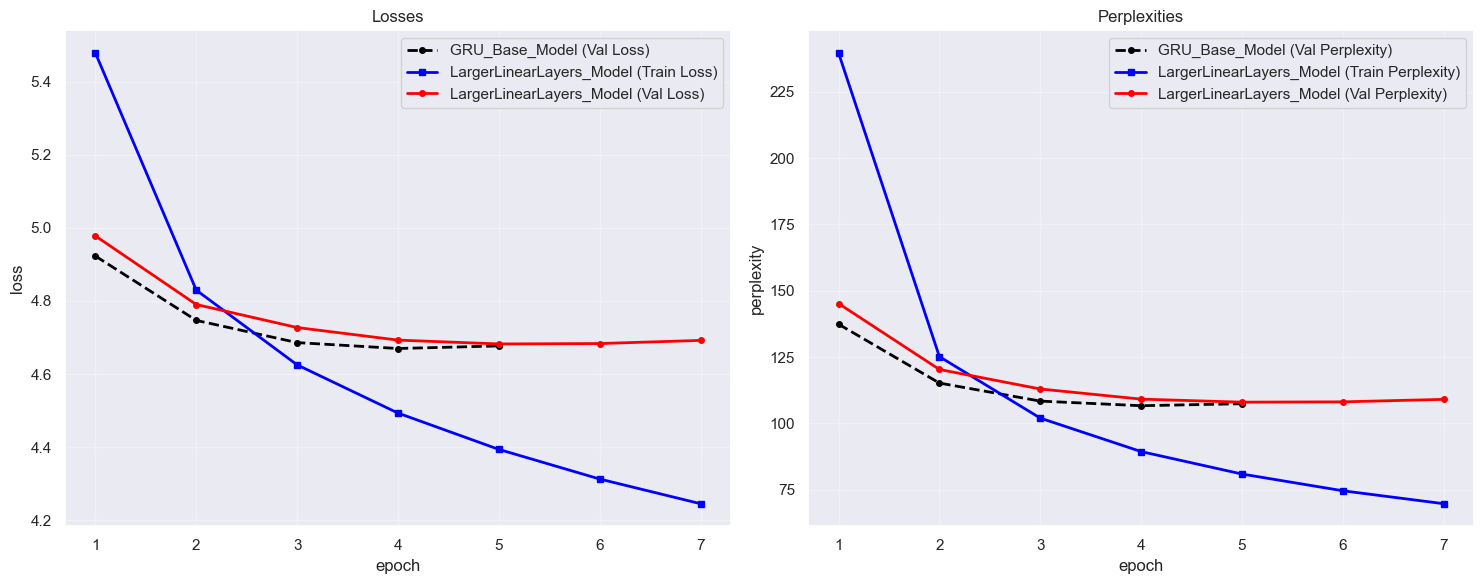

Loss = 4.68234362357702
Perplexity = 108.02294125313655

Сравнение с GRU_Base_Model:
Loss Хуже на 0.012478330196477927
Perplexity Хуже на 1.3395707448542282


In [38]:
set_seed(SEED)

model_name = 'LargerLinearLayers_Model'

model_larger_linear = LargerLinearLayers_LM(hidden_dim=256, vocab_size=len(vocab)).to(device)
criterion = nn.CrossEntropyLoss(ignore_index=word2ind['<pad>'])
optimizer = torch.optim.Adam(model_larger_linear.parameters())

larger_linear_losses, larger_linear_perplexities = train_model(model=model_larger_linear, 
                                                                criterion=criterion, 
                                                                optimizer=optimizer,
                                                                model_name=model_name,
                                                                plot=True,
                                                                num_epoch=NUM_EPOCH,
                                                                base_losses=base_losses,
                                                                base_perplexities=base_perplexities)

In [39]:
display(df_stats)

,Model,Loss,Perplexity,Diff_Loss,Diff_Perplexity,Better_than_base
0,GRU_Base_Model,4.669865,106.683371,0.000000,0.000000,False
1,LSTM_Model,4.633921,102.916831,-0.035944,-3.766540,True
2,MultiLayer_GRU_Model,4.669185,106.610808,-0.000680,-0.072562,True
3,LargerHiddenDim_Model,4.633033,102.825461,-0.036832,-3.857909,True
4,LargerLinearLayers_Model,4.682344,108.022941,0.012478,1.339571,False


### Использование альтернативной функции активации (GELU)

Применим функцию активации GELU вместо Tanh. <br>
Gaussian Error Linear Unit учитывает вероятностный характер нейронов.

In [40]:
class GELU_GRU_LM(nn.Module):

    def __init__(self, hidden_dim: int, vocab_size: int):
        super().__init__()
        self.embedding = nn.Embedding(vocab_size, hidden_dim)
        self.rnn = nn.GRU(hidden_dim, hidden_dim, batch_first=True)
        self.linear = nn.Linear(hidden_dim, hidden_dim)
        self.projection = nn.Linear(hidden_dim, vocab_size)

        self.non_lin = nn.GELU()    # GELU вместо Tanh
        self.dropout = nn.Dropout(p=0.1)

    def forward(self, input_batch) -> torch.Tensor:
        embeddings = self.embedding(input_batch)
        output, _ = self.rnn(embeddings)
        output = self.dropout(self.linear(self.non_lin(output)))
        projection = self.projection(self.non_lin(output))

        return projection

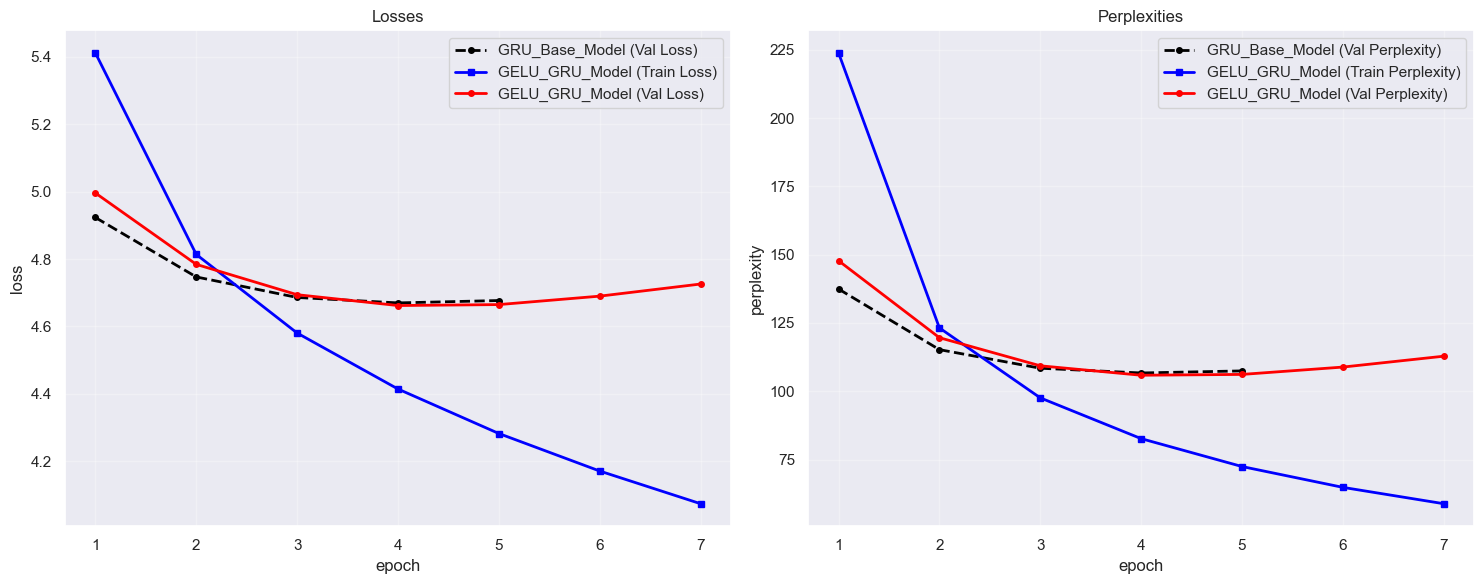

Loss = 4.662051433171982
Perplexity = 105.85300995011339

Сравнение с GRU_Base_Model:
Loss Лучше на 0.007813860208560008
Perplexity Лучше на 0.830360558168934


In [41]:
set_seed(SEED)

model_name = 'GELU_GRU_Model'

model_gelu = GELU_GRU_LM(hidden_dim=256, vocab_size=len(vocab)).to(device)
criterion = nn.CrossEntropyLoss(ignore_index=word2ind['<pad>'])
optimizer = torch.optim.Adam(model_gelu.parameters())

gelu_losses, gelu_perplexities = train_model(model=model_gelu, 
                                              criterion=criterion, 
                                              optimizer=optimizer,
                                              model_name=model_name,
                                              plot=True,
                                              num_epoch=NUM_EPOCH,
                                              base_losses=base_losses,
                                              base_perplexities=base_perplexities)

In [42]:
display(df_stats)

,Model,Loss,Perplexity,Diff_Loss,Diff_Perplexity,Better_than_base
0,GRU_Base_Model,4.669865,106.683371,0.000000,0.000000,False
1,LSTM_Model,4.633921,102.916831,-0.035944,-3.766540,True
2,MultiLayer_GRU_Model,4.669185,106.610808,-0.000680,-0.072562,True
3,LargerHiddenDim_Model,4.633033,102.825461,-0.036832,-3.857909,True
4,LargerLinearLayers_Model,4.682344,108.022941,0.012478,1.339571,False
5,GELU_GRU_Model,4.662051,105.853010,-0.007814,-0.830361,True


### Применение различных нормализаций

Увеличенние Dropout для регуляризации. <br>
Попробуем dropout = 0.3, тем самым уменьшим вероятность переобучения.

In [47]:
class LargerDropout_LM(nn.Module):
    def __init__(self, hidden_dim: int, vocab_size: int, dropout_rate: float = 0.2):
        super().__init__()
        self.embedding = nn.Embedding(vocab_size, hidden_dim)
        self.rnn = nn.GRU(hidden_dim, hidden_dim, batch_first=True)
        
        # Два линейных слоя и dropout_rate
        self.linear_layers = nn.Sequential(
            nn.Linear(hidden_dim, 2 * hidden_dim),
            nn.Tanh(),
            nn.Dropout(p=dropout_rate),
            nn.Linear(2 * hidden_dim, hidden_dim),
            nn.Tanh(),
            nn.Dropout(p=dropout_rate)
        )
        self.non_lin = nn.Tanh()
        self.projection = nn.Linear(hidden_dim, vocab_size)

    def forward(self, input_batch) -> torch.Tensor:
        embeddings = self.embedding(input_batch)
        output, _ = self.rnn(embeddings)
        output = self.linear_layers(output)
        projection = self.projection(self.non_lin(output))

        return projection

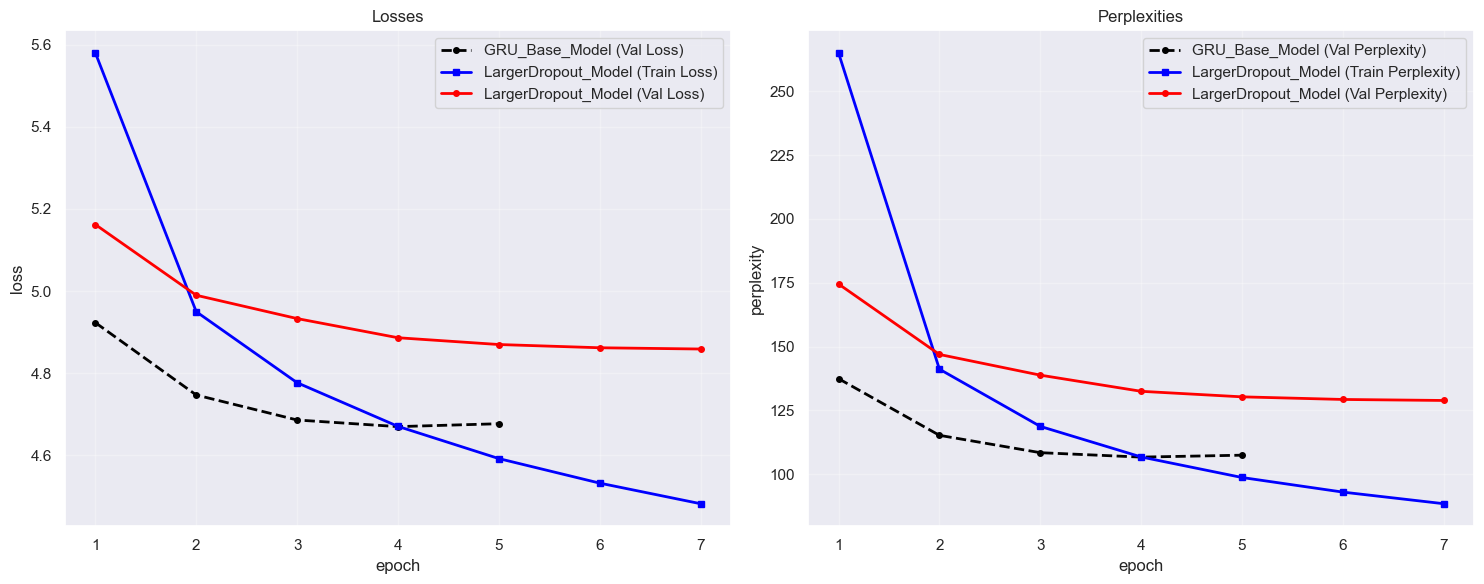

Loss = 4.858850093988272
Perplexity = 128.8759216723374

Сравнение с GRU_Base_Model:
Loss Хуже на 0.18898480060772993
Perplexity Хуже на 22.192551164055075


In [48]:
set_seed(SEED)

model_name = 'LargerDropout_Model'

model_larger_dropout = LargerDropout_LM(hidden_dim=256, vocab_size=len(vocab), dropout_rate=0.3).to(device)
criterion = nn.CrossEntropyLoss(ignore_index=word2ind['<pad>'])
optimizer = torch.optim.Adam(model_larger_dropout.parameters())

larger_dropout_losses, larger_dropout_perplexities = train_model(model=model_larger_dropout, 
                                                              criterion=criterion, 
                                                              optimizer=optimizer,
                                                              model_name=model_name,
                                                              plot=True,
                                                              num_epoch=NUM_EPOCH,
                                                              base_losses=base_losses,
                                                              base_perplexities=base_perplexities)

In [49]:
display(df_stats)

,Model,Loss,Perplexity,Diff_Loss,Diff_Perplexity,Better_than_base
0,GRU_Base_Model,4.669865,106.683371,0.000000,0.000000,False
1,LSTM_Model,4.633921,102.916831,-0.035944,-3.766540,True
2,MultiLayer_GRU_Model,4.669185,106.610808,-0.000680,-0.072562,True
3,LargerHiddenDim_Model,4.633033,102.825461,-0.036832,-3.857909,True
4,LargerLinearLayers_Model,4.682344,108.022941,0.012478,1.339571,False
5,GELU_GRU_Model,4.662051,105.853010,-0.007814,-0.830361,True
6,LargerDropout_Model,4.858850,128.875922,0.188985,22.192551,False


Добавление BatchNorm1d после RNN.

In [50]:
class BatchNorm_LM(nn.Module):
    def __init__(self, hidden_dim: int, vocab_size: int):
        super().__init__()
        self.embedding = nn.Embedding(vocab_size, hidden_dim)
        self.rnn = nn.GRU(hidden_dim, hidden_dim, batch_first=True)
        self.linear = nn.Linear(hidden_dim, hidden_dim)
        self.batch_norm = nn.BatchNorm1d(hidden_dim)    # BatchNorm
        self.projection = nn.Linear(hidden_dim, vocab_size)

        self.non_lin = nn.Tanh()
        self.dropout = nn.Dropout(p=0.1)

    def forward(self, input_batch) -> torch.Tensor:
        embeddings = self.embedding(input_batch)
        output, _ = self.rnn(embeddings)
        output = self.linear(output)

        output = output.transpose(1, 2)
        output = self.batch_norm(output)
        output = output.transpose(1, 2)
        
        output = self.dropout(self.non_lin(output))
        projection = self.projection(self.non_lin(output))

        return projection

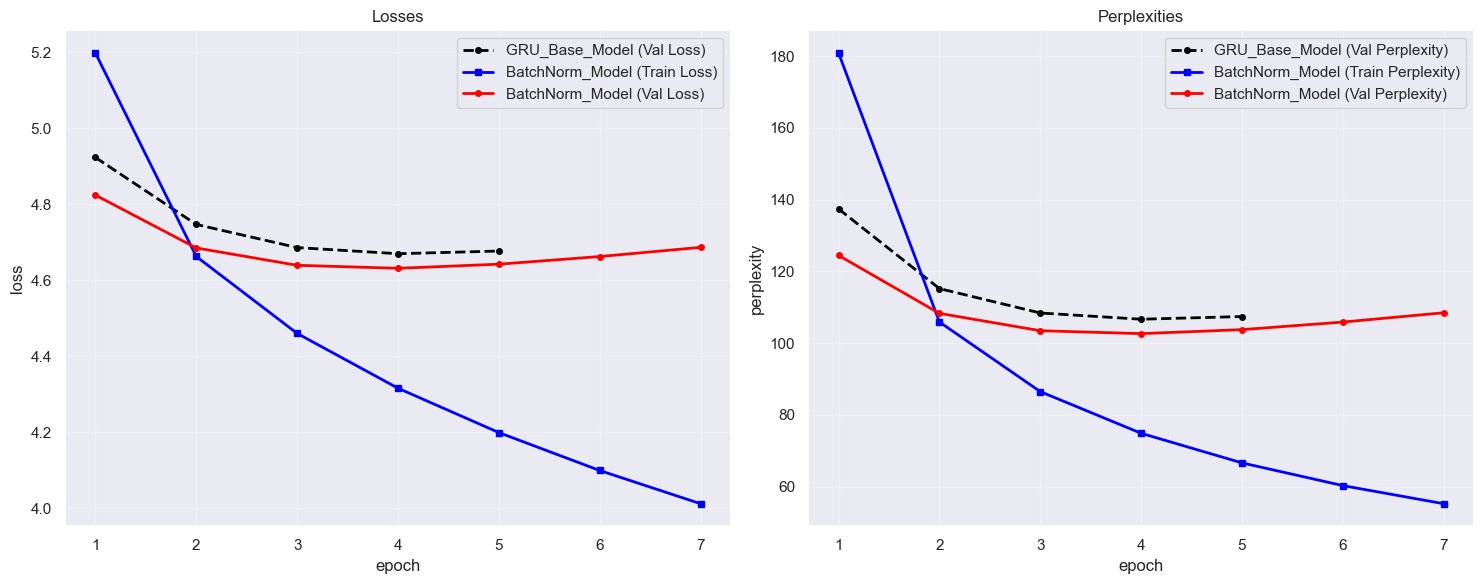

Loss = 4.631527090683962
Perplexity = 102.67073197534425

Сравнение с GRU_Base_Model:
Loss Лучше на 0.03833820269657995
Perplexity Лучше на 4.01263853293807


In [51]:
set_seed(SEED)

model_name = 'BatchNorm_Model'

model_batchnorm = BatchNorm_LM(hidden_dim=256, vocab_size=len(vocab)).to(device)
criterion = nn.CrossEntropyLoss(ignore_index=word2ind['<pad>'])
optimizer = torch.optim.Adam(model_batchnorm.parameters())

batchnorm_losses, batchnorm_perplexities = train_model(model=model_batchnorm, 
                                                        criterion=criterion, 
                                                        optimizer=optimizer,
                                                        model_name=model_name,
                                                        plot=True,
                                                        num_epoch=NUM_EPOCH,
                                                        base_losses=base_losses,
                                                        base_perplexities=base_perplexities)

In [52]:
display(df_stats)

,Model,Loss,Perplexity,Diff_Loss,Diff_Perplexity,Better_than_base
0,GRU_Base_Model,4.669865,106.683371,0.000000,0.000000,False
1,LSTM_Model,4.633921,102.916831,-0.035944,-3.766540,True
2,MultiLayer_GRU_Model,4.669185,106.610808,-0.000680,-0.072562,True
3,LargerHiddenDim_Model,4.633033,102.825461,-0.036832,-3.857909,True
4,LargerLinearLayers_Model,4.682344,108.022941,0.012478,1.339571,False
5,GELU_GRU_Model,4.662051,105.853010,-0.007814,-0.830361,True
6,LargerDropout_Model,4.858850,128.875922,0.188985,22.192551,False
7,BatchNorm_Model,4.631527,102.670732,-0.038338,-4.012639,True


Добавление LayerNorm после RNN. <br>
Предпочтительнее для моделей RNN, нежели BatchNorm.

In [53]:
class LayerNorm_LM(nn.Module):
    def __init__(self, hidden_dim: int, vocab_size: int):
        super().__init__()
        self.embedding = nn.Embedding(vocab_size, hidden_dim)
        self.rnn = nn.GRU(hidden_dim, hidden_dim, batch_first=True)
        self.layer_norm = nn.LayerNorm(hidden_dim)  # LayerNorm
        self.linear = nn.Linear(hidden_dim, hidden_dim)
        self.projection = nn.Linear(hidden_dim, vocab_size)

        self.non_lin = nn.Tanh()
        self.dropout = nn.Dropout(p=0.1)

    def forward(self, input_batch) -> torch.Tensor:
        embeddings = self.embedding(input_batch)
        output, _ = self.rnn(embeddings)
        output = self.layer_norm(output)
        output = self.dropout(self.linear(self.non_lin(output)))
        projection = self.projection(self.non_lin(output))

        return projection

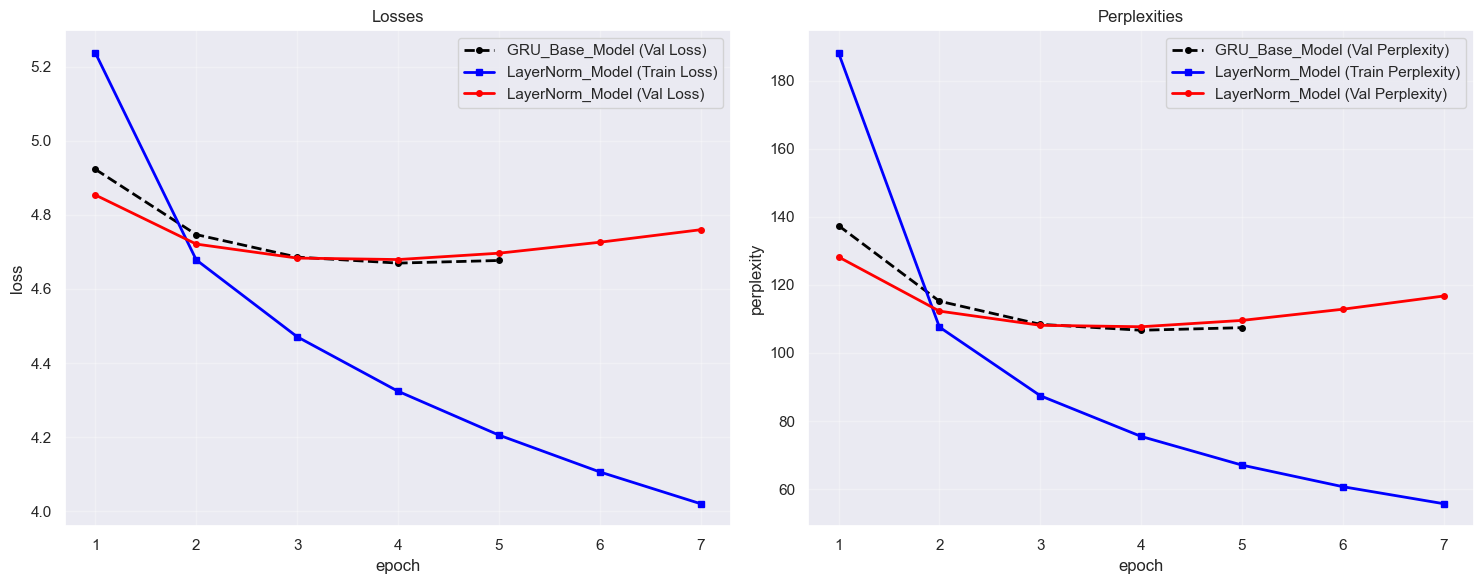

Loss = 4.679436035645314
Perplexity = 107.70931122719492

Сравнение с GRU_Base_Model:
Loss Хуже на 0.009570742264772392
Perplexity Хуже на 1.0259407189125938


In [54]:
set_seed(SEED)

model_name = 'LayerNorm_Model'

model_layernorm = LayerNorm_LM(hidden_dim=256, vocab_size=len(vocab)).to(device)
criterion = nn.CrossEntropyLoss(ignore_index=word2ind['<pad>'])
optimizer = torch.optim.Adam(model_layernorm.parameters())

layernorm_losses, layernorm_perplexities = train_model(model=model_layernorm, 
                                                        criterion=criterion, 
                                                        optimizer=optimizer,
                                                        model_name=model_name,
                                                        plot=True,
                                                        num_epoch=NUM_EPOCH,
                                                        base_losses=base_losses,
                                                        base_perplexities=base_perplexities)

In [55]:
display(df_stats)

,Model,Loss,Perplexity,Diff_Loss,Diff_Perplexity,Better_than_base
0,GRU_Base_Model,4.669865,106.683371,0.000000,0.000000,False
1,LSTM_Model,4.633921,102.916831,-0.035944,-3.766540,True
2,MultiLayer_GRU_Model,4.669185,106.610808,-0.000680,-0.072562,True
3,LargerHiddenDim_Model,4.633033,102.825461,-0.036832,-3.857909,True
4,LargerLinearLayers_Model,4.682344,108.022941,0.012478,1.339571,False
5,GELU_GRU_Model,4.662051,105.853010,-0.007814,-0.830361,True
6,LargerDropout_Model,4.858850,128.875922,0.188985,22.192551,False
7,BatchNorm_Model,4.631527,102.670732,-0.038338,-4.012639,True
8,LayerNorm_Model,4.679436,107.709311,0.009571,1.025941,False


### Увеличенние размера эмбеддингов

embedding_dim=512 для увеличения векотора предствления каждого слова. <br>
Для каждого слова кодируется больше информации.

In [56]:
class LargerEmbeddingDim_LM(nn.Module):
    def __init__(self, embedding_dim: int, hidden_dim: int, vocab_size: int):
        super().__init__()
        self.embedding = nn.Embedding(vocab_size, embedding_dim)
        self.rnn = nn.GRU(embedding_dim, hidden_dim, batch_first=True)
        self.linear = nn.Linear(hidden_dim, hidden_dim)
        self.projection = nn.Linear(hidden_dim, vocab_size)

        self.non_lin = nn.Tanh()
        self.dropout = nn.Dropout(p=0.1)

    def forward(self, input_batch) -> torch.Tensor:
        embeddings = self.embedding(input_batch)
        output, _ = self.rnn(embeddings)
        output = self.dropout(self.linear(self.non_lin(output)))
        projection = self.projection(self.non_lin(output))
        
        return projection

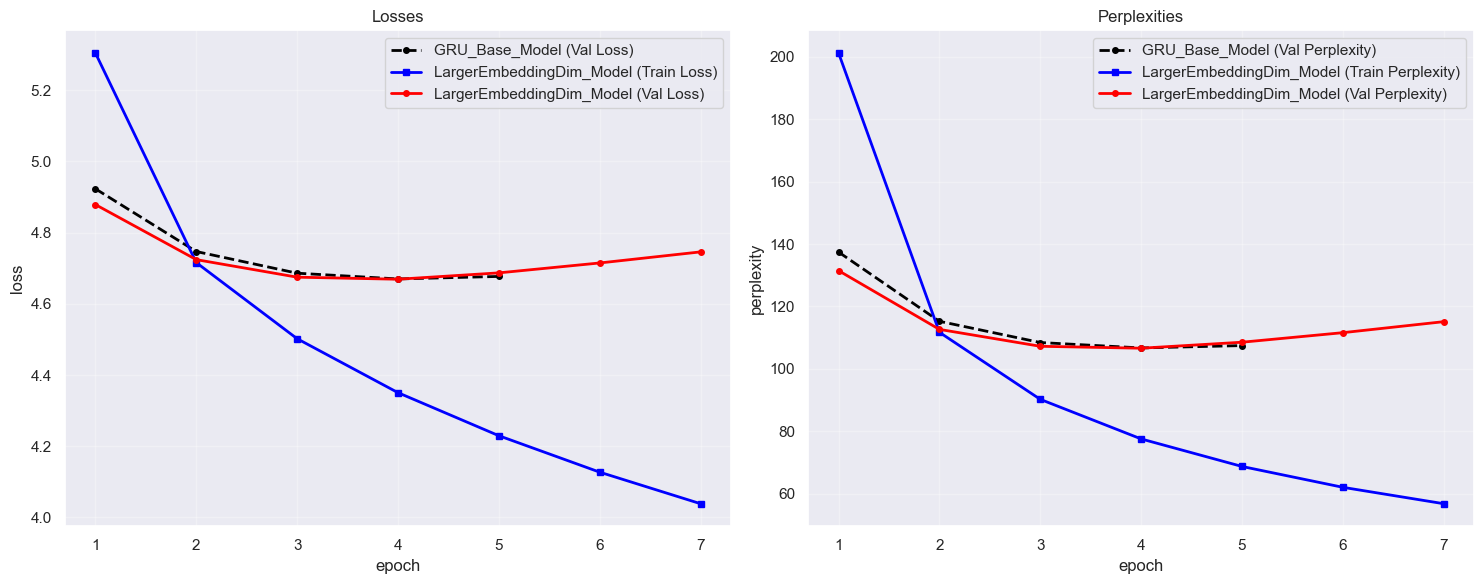

Loss = 4.669041905647669
Perplexity = 106.59556488370212

Сравнение с GRU_Base_Model:
Loss Лучше на 0.0008233877328729378
Perplexity Лучше на 0.08780562458019858


In [57]:
set_seed(SEED)

model_name = 'LargerEmbeddingDim_Model'

model_larger_emb = LargerEmbeddingDim_LM(embedding_dim=512, hidden_dim=256, vocab_size=len(vocab)).to(device) # embedding_dim=512
criterion = nn.CrossEntropyLoss(ignore_index=word2ind['<pad>'])
optimizer = torch.optim.Adam(model_larger_emb.parameters())

larger_emb_losses, larger_emb_perplexities = train_model(model=model_larger_emb, 
                                                          criterion=criterion, 
                                                          optimizer=optimizer,
                                                          model_name=model_name,
                                                          plot=True,
                                                          num_epoch=NUM_EPOCH,
                                                          base_losses=base_losses,
                                                          base_perplexities=base_perplexities)

In [58]:
display(df_stats)

,Model,Loss,Perplexity,Diff_Loss,Diff_Perplexity,Better_than_base
0,GRU_Base_Model,4.669865,106.683371,0.000000,0.000000,False
1,LSTM_Model,4.633921,102.916831,-0.035944,-3.766540,True
2,MultiLayer_GRU_Model,4.669185,106.610808,-0.000680,-0.072562,True
3,LargerHiddenDim_Model,4.633033,102.825461,-0.036832,-3.857909,True
4,LargerLinearLayers_Model,4.682344,108.022941,0.012478,1.339571,False
5,GELU_GRU_Model,4.662051,105.853010,-0.007814,-0.830361,True
6,LargerDropout_Model,4.858850,128.875922,0.188985,22.192551,False
7,BatchNorm_Model,4.631527,102.670732,-0.038338,-4.012639,True
8,LayerNorm_Model,4.679436,107.709311,0.009571,1.025941,False
9,LargerEmbeddingDim_Model,4.669042,106.595565,-0.000823,-0.087806,True


### Финальная модель (комбинирование подходов)

Хорошо показали себя подходы:
- Замена GRU на LSTM
- Использование сразу нескольких RNN блоков
- Увеличение размера скрытого состояния
- Применения нормализаций BatchNom и LayerNorm <br>
(выберем LayerNorm, потому что данная нормализация является лучшей практикой для RNN моделей)

Применим подходы в финальной модели:

In [61]:
class Combined_LM(nn.Module):
    def __init__(self, hidden_dim: int, vocab_size: int, num_layers: int = 1, dropout_rate: float = 0.1):
        super().__init__()
        self.embedding = nn.Embedding(vocab_size, hidden_dim)
        self.rnn = nn.LSTM(hidden_dim, hidden_dim, num_layers=num_layers,
                           batch_first=True, dropout=dropout_rate if num_layers > 1 else 0)
        
        # self.batch_norm = nn.BatchNorm1d(hidden_dim)    # BatchNorm
        self.layer_norm = nn.LayerNorm(hidden_dim)      # LayerNorm

        self.linear = nn.Linear(hidden_dim, hidden_dim)
        self.projection = nn.Linear(hidden_dim, vocab_size)
        
        self.non_lin = nn.Tanh()
        self.dropout = nn.Dropout(p=dropout_rate)
        
    def forward(self, input_batch) -> torch.Tensor:
        embeddings = self.embedding(input_batch)
        output, _ = self.rnn(embeddings)

        # output = output.transpose(1, 2)    # BatchNorm
        # output = self.batch_norm(output)    # BatchNorm
        # output = output.transpose(1, 2)    # BatchNorm

        output = self.layer_norm(output)    # LayerNorm

        output = self.dropout(self.linear(self.non_lin(output)))
        projection = self.projection(self.non_lin(output))

        return projection

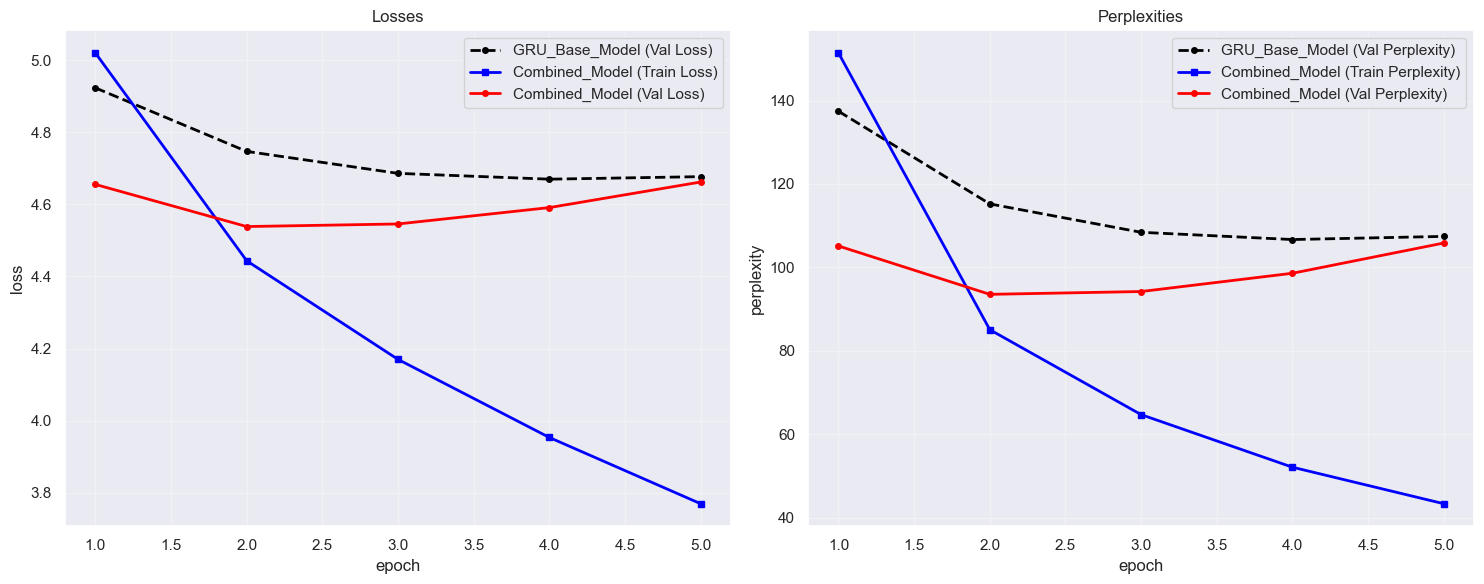

Loss = 4.538506110509236
Perplexity = 93.55094091090557

Сравнение с GRU_Base_Model:
Loss Лучше на 0.13135918287130544
Perplexity Лучше на 13.132429597376756


In [62]:
set_seed(SEED)

model_name = 'Combined_Model'

combined_model = Combined_LM(hidden_dim=512, vocab_size=len(vocab), num_layers=2).to(device)
criterion = nn.CrossEntropyLoss(ignore_index=word2ind['<pad>'])
optimizer = torch.optim.Adam(combined_model.parameters())
# optimizer = torch.optim.AdamW(combined_model.parameters(), lr=0.001, weight_decay=0.01)

combined_losses, combined_perplexities = train_model(model=combined_model,
                                                     criterion=criterion, 
                                                     optimizer=optimizer,
                                                     model_name=model_name,
                                                     plot=True,
                                                     num_epoch=NUM_EPOCH,
                                                     base_losses=base_losses,
                                                     base_perplexities=base_perplexities)

In [63]:
display(df_stats)

,Model,Loss,Perplexity,Diff_Loss,Diff_Perplexity,Better_than_base
0,GRU_Base_Model,4.669865,106.683371,0.000000,0.000000,False
1,LSTM_Model,4.633921,102.916831,-0.035944,-3.766540,True
2,MultiLayer_GRU_Model,4.669185,106.610808,-0.000680,-0.072562,True
3,LargerHiddenDim_Model,4.633033,102.825461,-0.036832,-3.857909,True
4,LargerLinearLayers_Model,4.682344,108.022941,0.012478,1.339571,False
5,GELU_GRU_Model,4.662051,105.853010,-0.007814,-0.830361,True
6,LargerDropout_Model,4.858850,128.875922,0.188985,22.192551,False
7,BatchNorm_Model,4.631527,102.670732,-0.038338,-4.012639,True
8,LayerNorm_Model,4.679436,107.709311,0.009571,1.025941,False
9,LargerEmbeddingDim_Model,4.669042,106.595565,-0.000823,-0.087806,True


In [64]:
class Combined_GELU_LM(nn.Module):
    def __init__(self, hidden_dim: int, vocab_size: int, num_layers: int = 1, dropout_rate: float = 0.1):
        super().__init__()
        self.embedding = nn.Embedding(vocab_size, hidden_dim)
        self.rnn = nn.LSTM(hidden_dim, hidden_dim, num_layers=num_layers,
                           batch_first=True, dropout=dropout_rate if num_layers > 1 else 0)
        
        # self.batch_norm = nn.BatchNorm1d(hidden_dim)    # BatchNorm
        self.layer_norm = nn.LayerNorm(hidden_dim)      # LayerNorm

        self.linear = nn.Linear(hidden_dim, hidden_dim)
        self.projection = nn.Linear(hidden_dim, vocab_size)
        
        self.non_lin = nn.GELU()
        self.dropout = nn.Dropout(p=dropout_rate)
        
    def forward(self, input_batch) -> torch.Tensor:
        embeddings = self.embedding(input_batch)
        output, _ = self.rnn(embeddings)

        # output = output.transpose(1, 2)    # BatchNorm
        # output = self.batch_norm(output)    # BatchNorm
        # output = output.transpose(1, 2)    # BatchNorm

        output = self.layer_norm(output)    # LayerNorm

        output = self.dropout(self.linear(self.non_lin(output)))
        projection = self.projection(self.non_lin(output))

        return projection

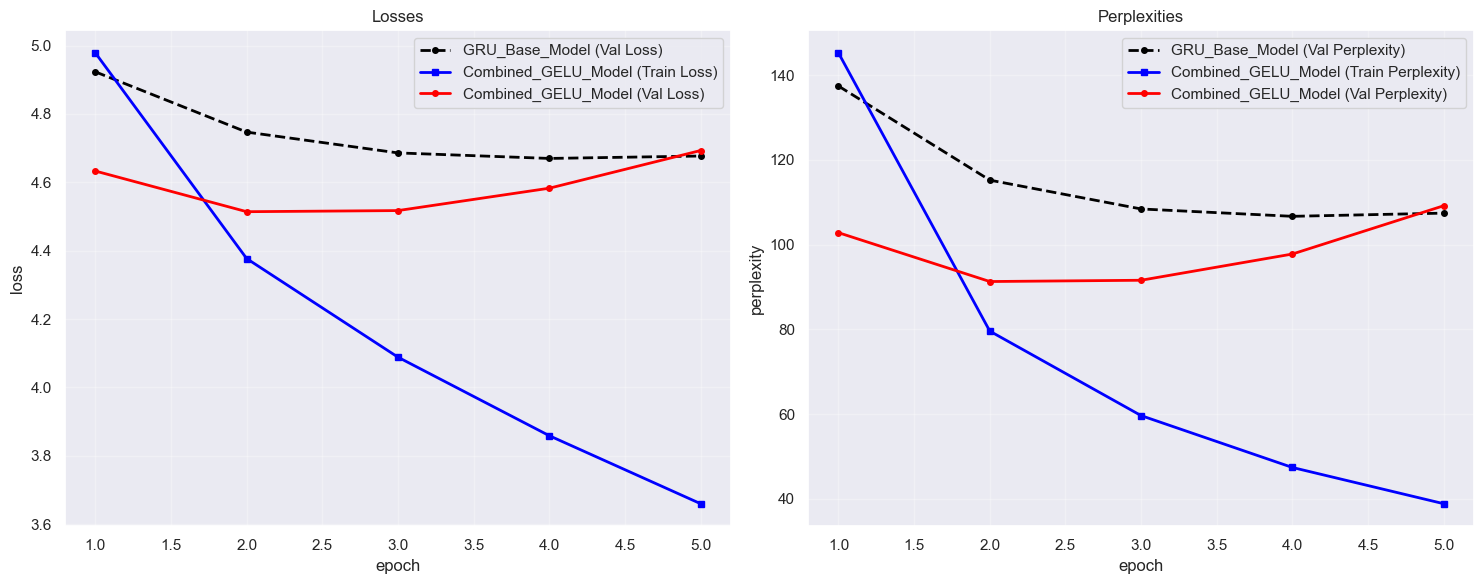

Loss = 4.51410018480741
Perplexity = 91.29538008184367

Сравнение с GRU_Base_Model:
Loss Лучше на 0.15576510857313153
Perplexity Лучше на 15.387990426438648


In [65]:
set_seed(SEED)

model_name = 'Combined_GELU_Model'

combined_gelu_model = Combined_GELU_LM(hidden_dim=512, vocab_size=len(vocab), num_layers=2).to(device)
criterion = nn.CrossEntropyLoss(ignore_index=word2ind['<pad>'])
optimizer = torch.optim.Adam(combined_gelu_model.parameters())
# optimizer = torch.optim.AdamW(combined_gelu_model.parameters(), lr=0.001, weight_decay=0.01)

combined_gelu_losses, combined_gelu_perplexities = train_model(model=combined_gelu_model,
                                                     criterion=criterion, 
                                                     optimizer=optimizer,
                                                     model_name=model_name,
                                                     plot=True,
                                                     num_epoch=NUM_EPOCH,
                                                     base_losses=base_losses,
                                                     base_perplexities=base_perplexities)

In [66]:
display(df_stats)

,Model,Loss,Perplexity,Diff_Loss,Diff_Perplexity,Better_than_base
0,GRU_Base_Model,4.669865,106.683371,0.000000,0.000000,False
1,LSTM_Model,4.633921,102.916831,-0.035944,-3.766540,True
2,MultiLayer_GRU_Model,4.669185,106.610808,-0.000680,-0.072562,True
3,LargerHiddenDim_Model,4.633033,102.825461,-0.036832,-3.857909,True
4,LargerLinearLayers_Model,4.682344,108.022941,0.012478,1.339571,False
5,GELU_GRU_Model,4.662051,105.853010,-0.007814,-0.830361,True
6,LargerDropout_Model,4.858850,128.875922,0.188985,22.192551,False
7,BatchNorm_Model,4.631527,102.670732,-0.038338,-4.012639,True
8,LayerNorm_Model,4.679436,107.709311,0.009571,1.025941,False
9,LargerEmbeddingDim_Model,4.669042,106.595565,-0.000823,-0.087806,True


### Отчет (2 балла)

Опишите проведенные эксперименты. Сравните перплексии полученных моделей. Предложите идеи по улучшению качества моделей.

Было реализовано:
- Базовая модель с одним GRU слоем. <br>
Все последующие реализации сравнивались с метриками данныой модели.
- Была опробована замена GRU слоя на LSTM слой. <br>
Модель показала значительно лучшие результаты. Модель борется с затухающими градиентами и лучше запоминает длинные зависимости.
- Использования двух GRU слоев. <br>
Заметно улучшение метрики Perplexity. Результат, возможно, будет лучше в связке с регуляризацями.
- Увеличение скрытого состояния с 256 до 512. <br>
Лучший результат. Модель смогла выучить более сложные зависимости.
- Добавление дополнительного линейного слоя и небольшим Dropout. <br>
Значение метрик хуже, чем в базовой модели.
- Замена функции активации Tanh на GELU. <br>
Значение метрик хуже, чем в базовой модели.
- Увеличение Dropout с 0.1 до 0.3. <br>
Значение метрик хуже, чем в базовой модели. Возможно, что модель недообучилась и необходим подбор оптимального значения Dropout.
- Добавлена Batch Normalization (нормализация активации по батчу). <br>
Значение метрик лучше, чем в базовой модели.
- Добавлена Layer Normalization (нормализация активации по каждому элементу батча). <br>
Значение метрик лучше, чем в базовой модели. Для RNN моделей предпочтительнее.
- Увеличение размерности эмбеддингов с 256 до 512. <br>
Значимого улучшения не последовало.

Реализация финальной модели Combined_Model, которая включает лучшие практики из числа проведенных экспериментов:
- Замена GRU слоя на LSTM слой
- Использования двух слоев RNN (два слоя LSTM)
- Использование размера скрытого слоя hidden_dim = 512
- Добавлена Layer Normalization

Модель показала лучшие значения метрики Perplexity (17.223330); <br>
Loss (2.379735) также оказался самым низким относительно Loss'a других моделей.

Предложения по улучшению:
- Подобрать оптимальный оптимизатор
- Подобрать оптимальные гиперпараметры
- Реализовать Early Stopping

# График сравнения всех моделей

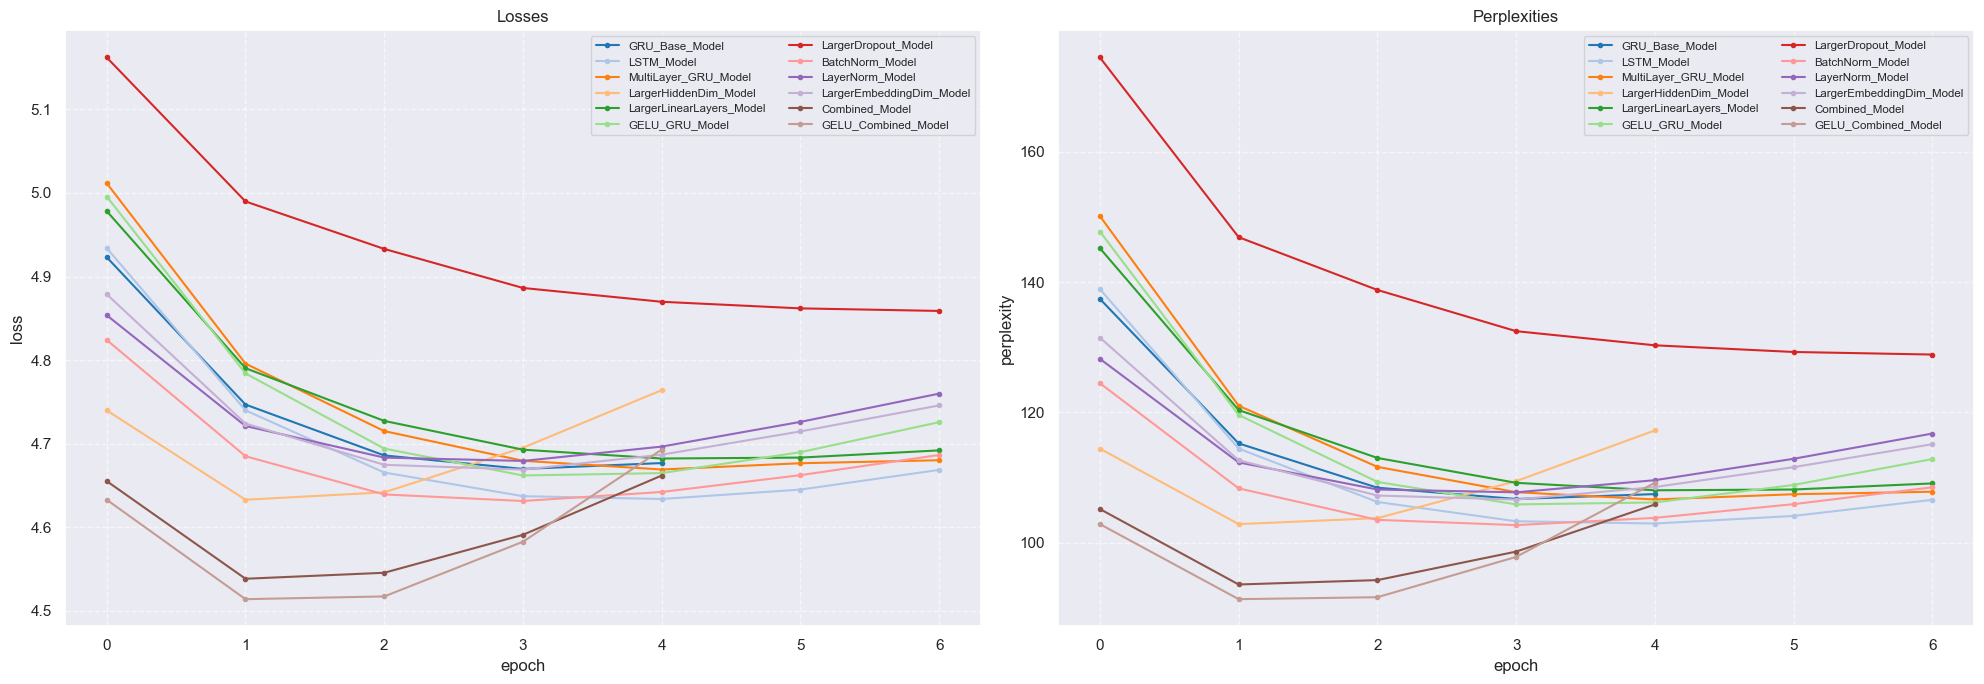

In [67]:
fig, axes = plt.subplots(nrows=1, ncols=2, figsize=(20, 7))

# Словарь со всеми моделями и полученными метриками
histories = {
    'GRU_Base_Model': (base_losses, base_perplexities),
    'LSTM_Model': (lstm_losses, lstm_perplexities),
    'MultiLayer_GRU_Model': (multilayer_losses, multilayer_perplexities),
    'LargerHiddenDim_Model': (larger_hidden_losses, larger_hidden_perplexities),
    'LargerLinearLayers_Model': (larger_linear_losses, larger_linear_perplexities),
    'GELU_GRU_Model': (gelu_losses, gelu_perplexities),
    'LargerDropout_Model': (larger_dropout_losses, larger_dropout_perplexities),
    'BatchNorm_Model': (batchnorm_losses, batchnorm_perplexities),
    'LayerNorm_Model': (layernorm_losses, layernorm_perplexities),
    'LargerEmbeddingDim_Model': (larger_emb_losses, larger_emb_perplexities),
    'Combined_Model': (combined_losses, combined_perplexities),
    'GELU_Combined_Model': (combined_gelu_losses, combined_gelu_perplexities)
}

colors = plt.cm.tab20.colors

for i, (model_name, (losses, perplexities)) in enumerate(histories.items()):
    color = colors[i % len(colors)]
    
    axes[0].plot(losses, color=color, marker='o', markersize=3, linewidth=1.5, label=model_name)
    axes[1].plot(perplexities, color=color, marker='o', markersize=3, linewidth=1.5, label=model_name)

axes[0].set_title('Losses')
axes[0].set_xlabel('epoch')
axes[0].set_ylabel('loss')
axes[0].grid(True, linestyle='--', alpha=0.6)
axes[0].legend(loc='upper right', fontsize='x-small', ncol=2)

axes[1].set_title('Perplexities')
axes[1].set_xlabel('epoch')
axes[1].set_ylabel('perplexity')
axes[1].grid(True, linestyle='--', alpha=0.6)
axes[1].legend(loc='upper right', fontsize='x-small', ncol=2)

plt.tight_layout()

plt.show();

Проверка на тесте

In [68]:
test_loss, test_perplexity = evaluate(combined_model, criterion, test_dataloader)

print(f'Loss на тесте: {test_loss}')
print(f'Perplexity на тесте: {test_perplexity}')

Loss на тесте: 4.528908249659416
Perplexity на тесте: 92.65734715168303


Попробуем сгенерировать продолжение предложений

In [69]:
def generate_sequence(model, starting_seq: str, max_seq_len: int = 50) -> str:
    device = 'cpu'
    model = model.to(device)
    
    # Разбиваем начальную строку на слова
    starting_words = word_tokenize(starting_seq.lower())
    
    input_ids = [word2ind['<bos>']] + [
        word2ind.get(word, word2ind['<unk>']) for word in starting_words]
    input_ids = torch.LongTensor(input_ids).to(device)
    
    model.eval()
    with torch.no_grad():
        for i in range(max_seq_len):
            output = model(input_ids.unsqueeze(0))
            next_word_distribution = output[0, -1, :]
            next_word = next_word_distribution.argmax()
            input_ids = torch.cat([input_ids, next_word.view(1)])

            if next_word.item() == word2ind['<eos>']:
                break

    words = ' '.join([ind2word[idx.item()] for idx in input_ids[1:]
                      if ind2word[idx.item()] not in ['<pad>', '<unk>', '<eos>']])
    
    return words

In [70]:
generate_sequence(combined_model, starting_seq='The filmmakers tried hard, but ')

"the filmmakers tried hard , but they were n't even remotely funny ."

In [71]:
generate_sequence(combined_model, starting_seq='never seen so many mistakes')

"never seen so many mistakes , but it 's not a bad movie ."

In [72]:
generate_sequence(combined_model, starting_seq='this film')

'this film is a very good movie .'

In [73]:
class Combined_LM(nn.Module):
    def __init__(self, hidden_dim: int, vocab_size: int, num_layers: int = 1, dropout_rate: float = 0.1):
        super().__init__()
        self.embedding = nn.Embedding(vocab_size, hidden_dim)
        self.rnn = nn.LSTM(hidden_dim, hidden_dim, num_layers=num_layers,
                           batch_first=True, dropout=dropout_rate if num_layers > 1 else 0)
        
        self.batch_norm = nn.BatchNorm1d(hidden_dim)    # BatchNorm
        # self.layer_norm = nn.LayerNorm(hidden_dim)      # LayerNorm

        self.linear = nn.Linear(hidden_dim, hidden_dim)
        self.projection = nn.Linear(hidden_dim, vocab_size)
        
        self.non_lin = nn.Tanh()
        self.dropout = nn.Dropout(p=dropout_rate)
        
    def forward(self, input_batch) -> torch.Tensor:
        embeddings = self.embedding(input_batch)
        output, _ = self.rnn(embeddings)


        output = self.linear(output)

        output = output.transpose(1, 2)    # BatchNorm
        output = self.batch_norm(output)    # BatchNorm
        output = output.transpose(1, 2)    # BatchNorm

        # output = self.layer_norm(output)    # LayerNorm

        output = self.dropout(self.linear(self.non_lin(output)))
        projection = self.projection(self.non_lin(output))

        return projection

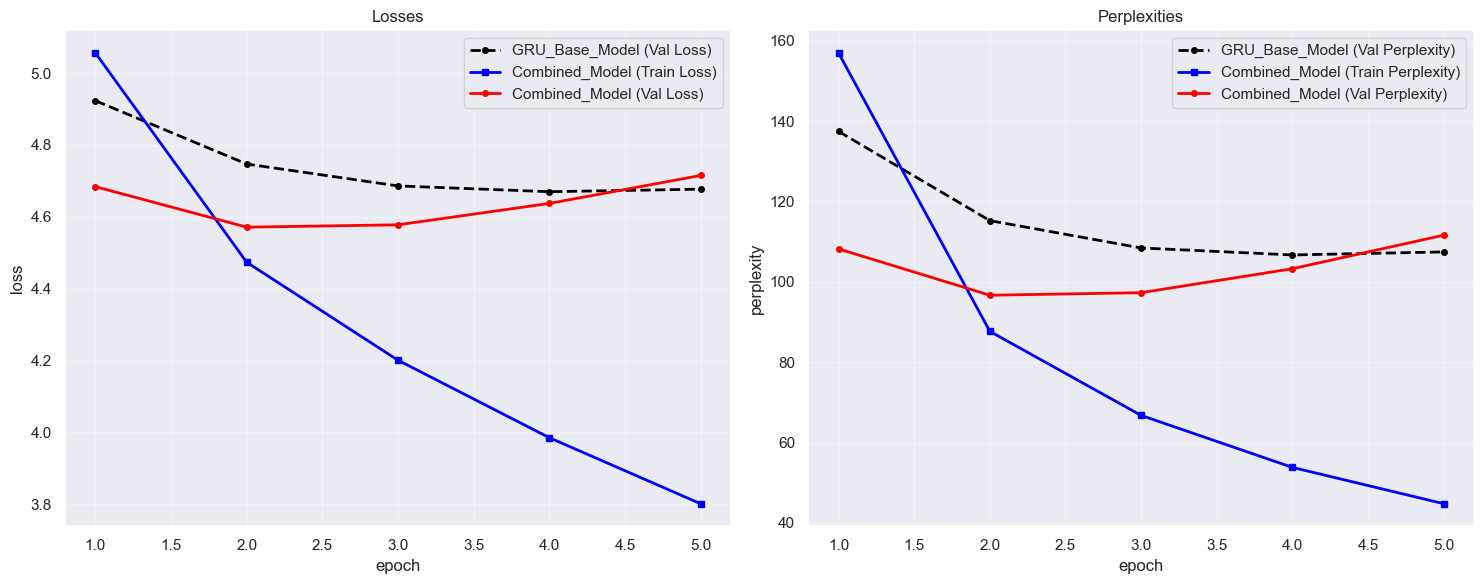

Loss = 4.571166631502983
Perplexity = 96.65680689795933

Сравнение с GRU_Base_Model:
Loss Лучше на 0.09869866187755871
Perplexity Лучше на 10.026563610322995


In [74]:
set_seed(SEED)

model_name = 'Combined_Model'

combined_model = Combined_LM(hidden_dim=512, vocab_size=len(vocab), num_layers=2).to(device)
criterion = nn.CrossEntropyLoss(ignore_index=word2ind['<pad>'])
optimizer = torch.optim.Adam(combined_model.parameters())
# optimizer = torch.optim.AdamW(combined_model.parameters(), lr=0.001, weight_decay=0.01)

combined_losses, combined_perplexities = train_model(model=combined_model,
                                                     criterion=criterion, 
                                                     optimizer=optimizer,
                                                     model_name=model_name,
                                                     plot=True,
                                                     num_epoch=NUM_EPOCH,
                                                     base_losses=base_losses,
                                                     base_perplexities=base_perplexities)

In [75]:
display(df_stats)

,Model,Loss,Perplexity,Diff_Loss,Diff_Perplexity,Better_than_base
0,GRU_Base_Model,4.669865,106.683371,0.000000,0.000000,False
1,LSTM_Model,4.633921,102.916831,-0.035944,-3.766540,True
2,MultiLayer_GRU_Model,4.669185,106.610808,-0.000680,-0.072562,True
3,LargerHiddenDim_Model,4.633033,102.825461,-0.036832,-3.857909,True
4,LargerLinearLayers_Model,4.682344,108.022941,0.012478,1.339571,False
5,GELU_GRU_Model,4.662051,105.853010,-0.007814,-0.830361,True
6,LargerDropout_Model,4.858850,128.875922,0.188985,22.192551,False
7,BatchNorm_Model,4.631527,102.670732,-0.038338,-4.012639,True
8,LayerNorm_Model,4.679436,107.709311,0.009571,1.025941,False
9,LargerEmbeddingDim_Model,4.669042,106.595565,-0.000823,-0.087806,True


In [76]:
class Combined_GELU_LM(nn.Module):
    def __init__(self, hidden_dim: int, vocab_size: int, num_layers: int = 1, dropout_rate: float = 0.1):
        super().__init__()
        self.embedding = nn.Embedding(vocab_size, hidden_dim)
        self.rnn = nn.LSTM(hidden_dim, hidden_dim, num_layers=num_layers,
                           batch_first=True, dropout=dropout_rate if num_layers > 1 else 0)
        
        self.batch_norm = nn.BatchNorm1d(hidden_dim)    # BatchNorm
        # self.layer_norm = nn.LayerNorm(hidden_dim)      # LayerNorm

        self.linear = nn.Linear(hidden_dim, hidden_dim)
        self.projection = nn.Linear(hidden_dim, vocab_size)
        
        self.non_lin = nn.GELU()
        self.dropout = nn.Dropout(p=dropout_rate)
        
    def forward(self, input_batch) -> torch.Tensor:
        embeddings = self.embedding(input_batch)
        output, _ = self.rnn(embeddings)


        output = self.linear(output)

        output = output.transpose(1, 2)    # BatchNorm
        output = self.batch_norm(output)    # BatchNorm
        output = output.transpose(1, 2)    # BatchNorm

        # output = self.layer_norm(output)    # LayerNorm

        output = self.dropout(self.linear(self.non_lin(output)))
        projection = self.projection(self.non_lin(output))

        return projection

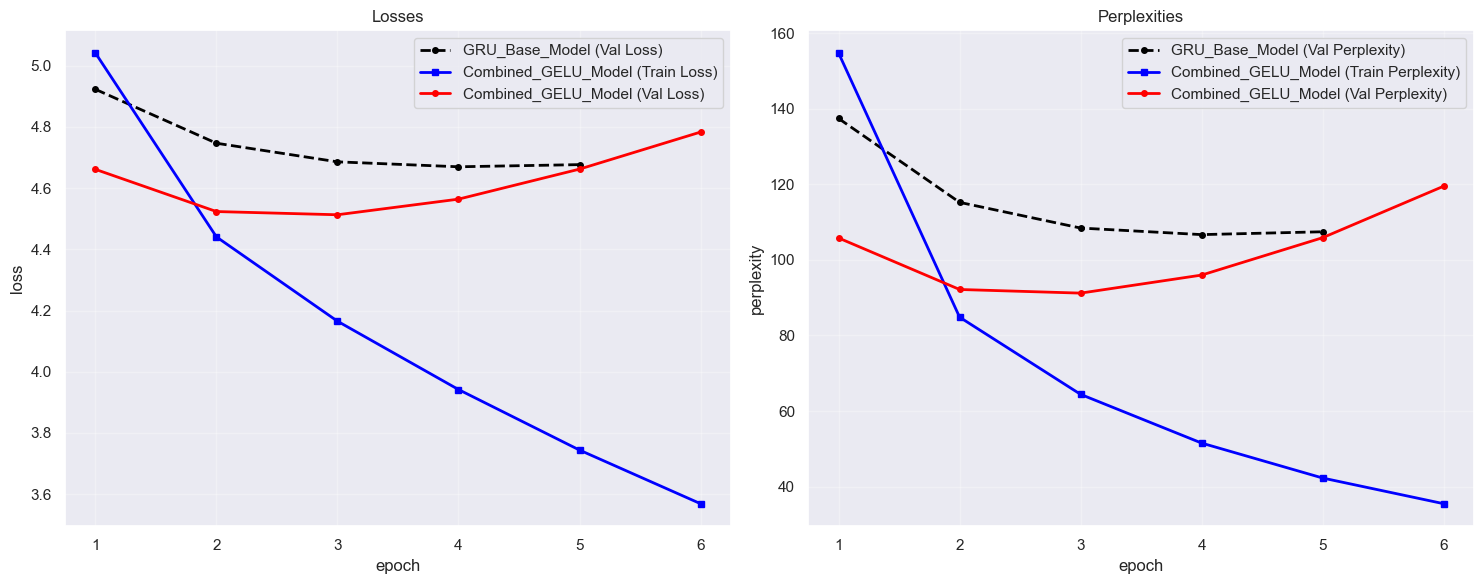

Loss = 4.513074061809442
Perplexity = 91.2017478400474

Сравнение с GRU_Base_Model:
Loss Лучше на 0.1567912315711002
Perplexity Лучше на 15.48162266823492


In [77]:
set_seed(SEED)

model_name = 'Combined_GELU_Model'

combined_gelu_model = Combined_GELU_LM(hidden_dim=512, vocab_size=len(vocab), num_layers=2).to(device)
criterion = nn.CrossEntropyLoss(ignore_index=word2ind['<pad>'])
optimizer = torch.optim.Adam(combined_gelu_model.parameters())
# optimizer = torch.optim.AdamW(combined_gelu_model.parameters(), lr=0.001, weight_decay=0.01)

combined_gelu_losses, combined_gelu_perplexities = train_model(model=combined_gelu_model,
                                                     criterion=criterion, 
                                                     optimizer=optimizer,
                                                     model_name=model_name,
                                                     plot=True,
                                                     num_epoch=NUM_EPOCH,
                                                     base_losses=base_losses,
                                                     base_perplexities=base_perplexities)

In [78]:
display(df_stats)

,Model,Loss,Perplexity,Diff_Loss,Diff_Perplexity,Better_than_base
0,GRU_Base_Model,4.669865,106.683371,0.000000,0.000000,False
1,LSTM_Model,4.633921,102.916831,-0.035944,-3.766540,True
2,MultiLayer_GRU_Model,4.669185,106.610808,-0.000680,-0.072562,True
3,LargerHiddenDim_Model,4.633033,102.825461,-0.036832,-3.857909,True
4,LargerLinearLayers_Model,4.682344,108.022941,0.012478,1.339571,False
5,GELU_GRU_Model,4.662051,105.853010,-0.007814,-0.830361,True
6,LargerDropout_Model,4.858850,128.875922,0.188985,22.192551,False
7,BatchNorm_Model,4.631527,102.670732,-0.038338,-4.012639,True
8,LayerNorm_Model,4.679436,107.709311,0.009571,1.025941,False
9,LargerEmbeddingDim_Model,4.669042,106.595565,-0.000823,-0.087806,True
